# **Problem Statement**

## Business Context

A sales forecast is a prediction of future sales revenue based on historical data, industry trends, and the status of the current sales pipeline. Businesses use the sales forecast to estimate weekly, monthly, quarterly, and annual sales totals. A company needs to make an accurate sales forecast as it adds value across an organization and helps the different verticals to chalk out their future course of action.

Forecasting helps an organization plan its sales operations by region and provides valuable insights to the supply chain team regarding the procurement of goods and materials. An accurate sales forecast process has many benefits which include improved decision-making about the future and reduction of sales pipeline and forecast risks. Moreover, it helps to reduce the time spent in planning territory coverage and establish benchmarks that can be used to assess trends in the future.

## Objective

SuperKart is a retail chain operating supermarkets and food marts across various tier cities, offering a wide range of products. To optimize its inventory management and make informed decisions around regional sales strategies, SuperKart wants to accurately forecast the sales revenue of its outlets for the upcoming quarter.

To operationalize these insights at scale, the company has partnered with a data science firm—not just to build a predictive model based on historical sales data, but to develop and deploy a robust forecasting solution that can be integrated into SuperKart’s decision-making systems and used across its network of stores.

## Data Description

The data contains the different attributes of the various products and stores.The detailed data dictionary is given below.

- **Product_Id** - unique identifier of each product, each identifier having two letters at the beginning followed by a number.
- **Product_Weight** - weight of each product
- **Product_Sugar_Content** - sugar content of each product like low sugar, regular and no sugar
- **Product_Allocated_Area** - ratio of the allocated display area of each product to the total display area of all the products in a store
- **Product_Type** - broad category for each product like meat, snack foods, hard drinks, dairy, canned, soft drinks, health and hygiene, baking goods, bread, breakfast, frozen foods, fruits and vegetables, household, seafood, starchy foods, others
- **Product_MRP** - maximum retail price of each product
- **Store_Id** - unique identifier of each store
- **Store_Establishment_Year** - year in which the store was established
- **Store_Size** - size of the store depending on sq. feet like high, medium and low
- **Store_Location_City_Type** - type of city in which the store is located like Tier 1, Tier 2 and Tier 3. Tier 1 consists of cities where the standard of living is comparatively higher than its Tier 2 and Tier 3 counterparts.
- **Store_Type** - type of store depending on the products that are being sold there like Departmental Store, Supermarket Type 1, Supermarket Type 2 and Food Mart
- **Product_Store_Sales_Total** - total revenue generated by the sale of that particular product in that particular store


# **Installing and Importing the necessary libraries**

In [1]:
# Installing the libraries with the specified versions
# (numpy 2.1.3 / pandas 2.2.3 are the closest releases to the template pins that support Colab's Python 3.13)
!pip install numpy==2.1.3 pandas==2.2.3 scikit-learn==1.6.1 matplotlib==3.10.0 seaborn==0.13.2 joblib==1.4.2 xgboost==2.1.4 requests==2.32.4 huggingface_hub==0.34.0 -q

**Note:**

- After running the above cell, kindly restart the notebook kernel (for Jupyter Notebook) or runtime (for Google Colab) and run all cells sequentially from the next cell.

- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in this notebook.

In [1]:
import warnings
warnings.filterwarnings("ignore")

# Libraries to help with reading and manipulating data
import numpy as np
import pandas as pd

# For splitting the dataset
from sklearn.model_selection import train_test_split

# Libaries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Removes the limit for the number of displayed columns
pd.set_option("display.max_columns", None)
# Sets the limit for the number of displayed rows
pd.set_option("display.max_rows", 100)


# Libraries different ensemble classifiers
from sklearn.ensemble import (
    BaggingRegressor,
    RandomForestRegressor,
    AdaBoostRegressor,
    GradientBoostingRegressor,
)
from xgboost import XGBRegressor
from sklearn.tree import DecisionTreeRegressor

# Libraries to get different metric scores
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    mean_absolute_percentage_error
)

# To create the pipeline
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline,Pipeline

# To tune different models and standardize
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler,OneHotEncoder

# To serialize the model
import joblib

# os related functionalities
import os

# API request
import requests

# for hugging face space authentication to upload files
from huggingface_hub import login, HfApi

In [2]:
# Render every inline figure at its full figsize (Colab's inline backend otherwise crops each figure
# to its content, which gives charts of unequal width in the exported HTML)
get_ipython().run_line_magic("config", "InlineBackend.print_figure_kwargs = {'bbox_inches': None}")

sns.set_theme(style="whitegrid", palette="deep")
FIG_W = 12  # one common width for every chart in the notebook
RANDOM_STATE = 1

# Cross-validation splitter for hyperparameter tuning
from sklearn.model_selection import KFold

# **Loading the dataset**

In [3]:
# In Colab, mount Google Drive and copy the two data files from MyDrive/SuperKart into the working
# directory (outside Colab the files are expected in the working directory already)
import shutil
try:
    from google.colab import drive
    drive.mount("/content/drive")
    for file_name in ["SuperKart.csv", "Batch_Data_SuperKart.csv"]:
        shutil.copy(f"/content/drive/MyDrive/SuperKart/{file_name}", file_name)
except ImportError:
    pass

# Read the historical sales data
kart = pd.read_csv("SuperKart.csv")

# Work on a copy so the raw data stays untouched
data = kart.copy()

Mounted at /content/drive


# **Data Overview**

In [4]:
# First and last five rows
data.head()

,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total
0,FD6114,12.66,Low Sugar,0.027,Frozen Foods,117.08,OUT004,2009,Medium,Tier 2,Supermarket Type2,2842.40
1,FD7839,16.54,Low Sugar,0.144,Dairy,171.43,OUT003,1999,Medium,Tier 1,Departmental Store,4830.02
2,FD5075,14.28,Regular,0.031,Canned,162.08,OUT001,1987,High,Tier 2,Supermarket Type1,4130.16
3,FD8233,12.10,Low Sugar,0.112,Baking Goods,186.31,OUT001,1987,High,Tier 2,Supermarket Type1,4132.18
4,NC1180,9.57,No Sugar,0.010,Health and Hygiene,123.67,OUT002,1998,Small,Tier 3,Food Mart,2279.36


In [5]:
data.tail()

,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total
8758,NC7546,14.80,No Sugar,0.016,Health and Hygiene,140.53,OUT004,2009,Medium,Tier 2,Supermarket Type2,3806.53
8759,NC584,14.06,No Sugar,0.142,Household,144.51,OUT004,2009,Medium,Tier 2,Supermarket Type2,5020.74
8760,NC2471,13.48,No Sugar,0.017,Health and Hygiene,88.58,OUT001,1987,High,Tier 2,Supermarket Type1,2443.42
8761,NC7187,13.89,No Sugar,0.193,Household,168.44,OUT001,1987,High,Tier 2,Supermarket Type1,4171.82
8762,FD306,14.73,Low Sugar,0.177,Snack Foods,224.93,OUT002,1998,Small,Tier 3,Food Mart,2186.08


In [6]:
# Number of rows and columns
print(f"The dataset has {data.shape[0]} rows and {data.shape[1]} columns.")

The dataset has 8763 rows and 12 columns.


In [7]:
# Column data types and non-null counts
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8763 entries, 0 to 8762
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Product_Id                 8763 non-null   object 
 1   Product_Weight             8763 non-null   float64
 2   Product_Sugar_Content      8763 non-null   object 
 3   Product_Allocated_Area     8763 non-null   float64
 4   Product_Type               8763 non-null   object 
 5   Product_MRP                8763 non-null   float64
 6   Store_Id                   8763 non-null   object 
 7   Store_Establishment_Year   8763 non-null   int64  
 8   Store_Size                 8763 non-null   object 
 9   Store_Location_City_Type   8763 non-null   object 
 10  Store_Type                 8763 non-null   object 
 11  Product_Store_Sales_Total  8763 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 821.7+ KB


**Observations**
- 8,763 product–store records and 12 columns: 7 categorical (object) and 5 numeric.
- No column has null values, so no imputation is needed.
- `Product_Store_Sales_Total` is the continuous target, which makes this a **regression** problem.

In [8]:
# Statistical summary of the numeric columns
data.describe().T

,count,mean,std,min,25%,50%,75%,max
Product_Weight,8763.0,12.653792,2.217320,4.000,11.150,12.660,14.180,22.000
Product_Allocated_Area,8763.0,0.068786,0.048204,0.004,0.031,0.056,0.096,0.298
Product_MRP,8763.0,147.032539,30.694110,31.000,126.160,146.740,167.585,266.000
Store_Establishment_Year,8763.0,2002.032751,8.388381,1987.000,1998.000,2009.000,2009.000,2009.000
Product_Store_Sales_Total,8763.0,3464.003640,1065.630494,33.000,2761.715,3452.340,4145.165,8000.000


**Observations**
- **Product_Weight** ranges from 4 to 22 with a mean of about 12.65, and its mean and median are almost the same, so the distribution is symmetric.
- **Product_Allocated_Area** is small (mean 0.069, max 0.298). Each product takes only a few percent of a store's display space.
- **Product_MRP** ranges from 31 to 266 with a mean of about 147.
- **Store_Establishment_Year** ranges from 1987 to 2009. Its 50th and 75th percentiles are both 2009, which means most rows come from a single store that opened in 2009.
- **Product_Store_Sales_Total** ranges from about 33 to 8,000 with a mean of about 3,464.

In [9]:
# Summary of the categorical columns
data.describe(include="object").T

,count,unique,top,freq
Product_Id,8763,8763,FD306,1
Product_Sugar_Content,8763,4,Low Sugar,4885
Product_Type,8763,16,Fruits and Vegetables,1249
Store_Id,8763,4,OUT004,4676
Store_Size,8763,3,Medium,6025
Store_Location_City_Type,8763,3,Tier 2,6262
Store_Type,8763,4,Supermarket Type2,4676


In [10]:
# Missing values and duplicate rows
print("Missing values per column:")
print(data.isnull().sum())
print(f"\nDuplicate rows: {data.duplicated().sum()}")
print(f"Unique Product_Id values: {data['Product_Id'].nunique()} (rows: {len(data)})")

Missing values per column:
Product_Id                   0
Product_Weight               0
Product_Sugar_Content        0
Product_Allocated_Area       0
Product_Type                 0
Product_MRP                  0
Store_Id                     0
Store_Establishment_Year     0
Store_Size                   0
Store_Location_City_Type     0
Store_Type                   0
Product_Store_Sales_Total    0
dtype: int64

Duplicate rows: 0
Unique Product_Id values: 8763 (rows: 8763)


In [11]:
# Levels of every categorical column (Product_Id excluded - it is unique per row)
cat_cols = data.select_dtypes(include="object").columns.drop("Product_Id")
for col in cat_cols:
    print(data[col].value_counts(), "\n" + "-" * 50)

Product_Sugar_Content
Low Sugar    4885
Regular      2251
No Sugar     1519
reg           108
Name: count, dtype: int64 
--------------------------------------------------
Product_Type
Fruits and Vegetables    1249
Snack Foods              1149
Frozen Foods              811
Dairy                     796
Household                 740
Baking Goods              716
Canned                    677
Health and Hygiene        628
Meat                      618
Soft Drinks               519
Breads                    200
Hard Drinks               186
Others                    151
Starchy Foods             141
Breakfast                 106
Seafood                    76
Name: count, dtype: int64 
--------------------------------------------------
Store_Id
OUT004    4676
OUT001    1586
OUT003    1349
OUT002    1152
Name: count, dtype: int64 
--------------------------------------------------
Store_Size
Medium    6025
High      1586
Small     1152
Name: count, dtype: int64 
---------------------------

In [12]:
# The first two letters of Product_Id encode a product family
data["Product_Id"].str[:2].value_counts()

,count
Product_Id,
FD,6539
NC,1519
DR,705


**Observations**
- There are no missing values and no duplicate rows.
- **Product_Id is unique on every row (8,763 values)**, so it has no predictive value as an identifier. Its two-letter prefix, though, is a meaningful product family: **FD** (food, 6,539), **NC** (non-consumable, 1,519) and **DR** (drinks, 705).
- **Product_Sugar_Content** has an inconsistent label: `reg` (108 rows) is the same as `Regular` and is fixed during preprocessing.
- There are only **four stores**. OUT004 alone contributes 4,676 rows (53%).
- Store_Size, Store_Location_City_Type and Store_Type have exactly as many effective levels as there are stores. This is checked during the bivariate analysis.

# **Exploratory Data Analysis (EDA)**

## Univariate Analysis

In [13]:
def histogram_boxplot(data, feature, bins="auto", kde=True):
    """Boxplot (top) and histogram (bottom) of a numeric feature on a shared x-axis."""
    fig, (ax_box, ax_hist) = plt.subplots(
        nrows=2, sharex=True, gridspec_kw={"height_ratios": (0.25, 0.75)}, figsize=(FIG_W, 6)
    )
    sns.boxplot(data=data, x=feature, ax=ax_box, showmeans=True, color="violet")
    sns.histplot(data=data, x=feature, kde=kde, ax=ax_hist, bins=bins)
    ax_hist.axvline(data[feature].mean(), color="green", linestyle="--", label="Mean")
    ax_hist.axvline(data[feature].median(), color="black", linestyle="-", label="Median")
    ax_hist.legend()
    ax_box.set_title(f"Distribution of {feature}")
    plt.tight_layout()
    plt.show()


def labeled_barplot(data, feature, perc=True):
    """Count plot of a categorical feature, with each bar labelled by its share or count."""
    total = len(data[feature])
    order = data[feature].value_counts().index
    plt.figure(figsize=(FIG_W, 5))
    ax = sns.countplot(data=data, x=feature, order=order, hue=feature, legend=False, palette="Paired")
    for p in ax.patches:
        label = f"{100 * p.get_height() / total:.1f}%" if perc else int(p.get_height())
        ax.annotate(label, (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=10)
    plt.xticks(rotation=90 if data[feature].nunique() > 6 else 0)
    plt.title(f"Distribution of {feature}")
    plt.tight_layout()
    plt.show()

### Numeric features

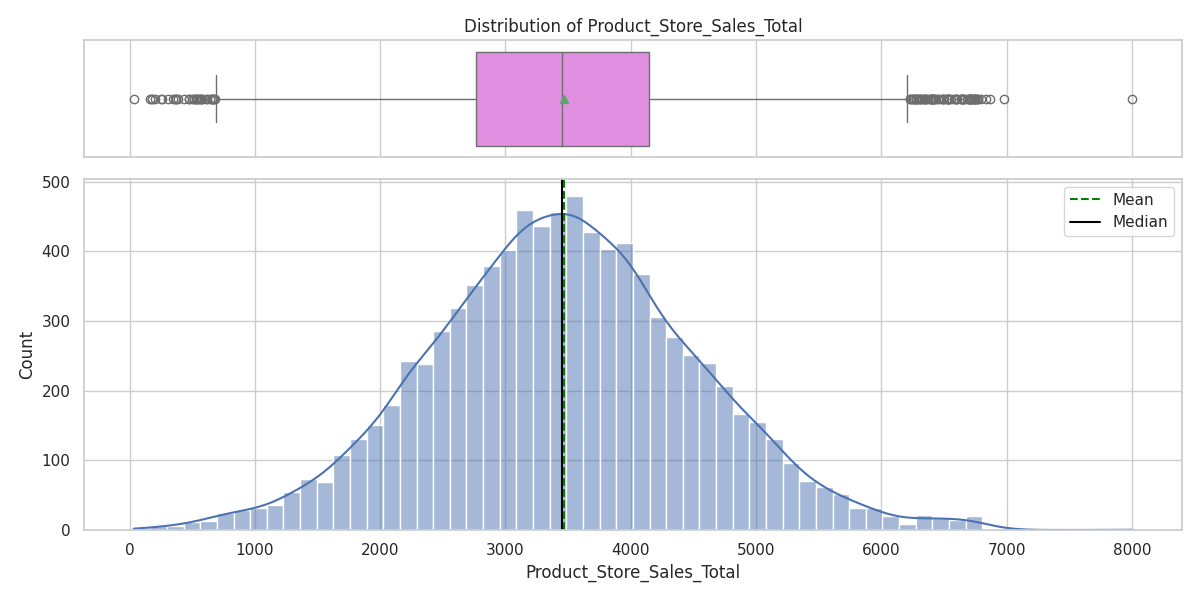

In [14]:
histogram_boxplot(data, "Product_Store_Sales_Total")

**Observations**
- The target is close to normally distributed (skewness ≈ 0.09), with mean and median both near 3,450.
- Outliers sit at both ends of the IQR fences: totals below about 690 and above about 6,220, up to a maximum of 8,000. These are real sales outcomes, not data errors, so they are kept.

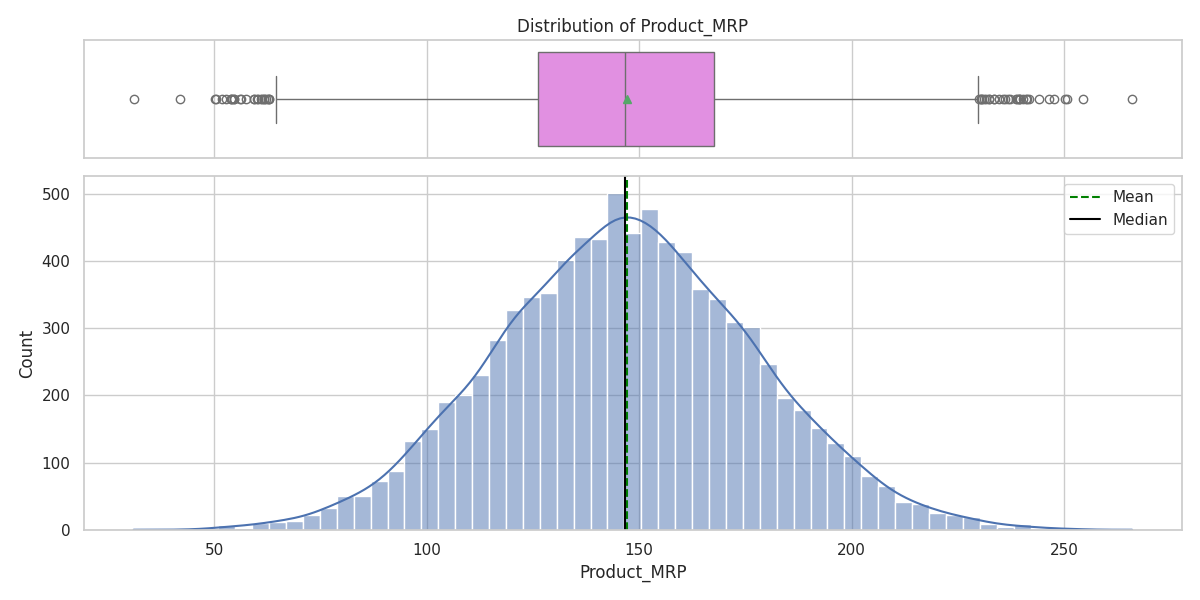

In [15]:
histogram_boxplot(data, "Product_MRP")

**Observations**
- Product_MRP is symmetric around a mean of about 147, with a few outliers at both ends (below about 64 and above about 230). These are plausible prices for premium and budget items, so they are kept.

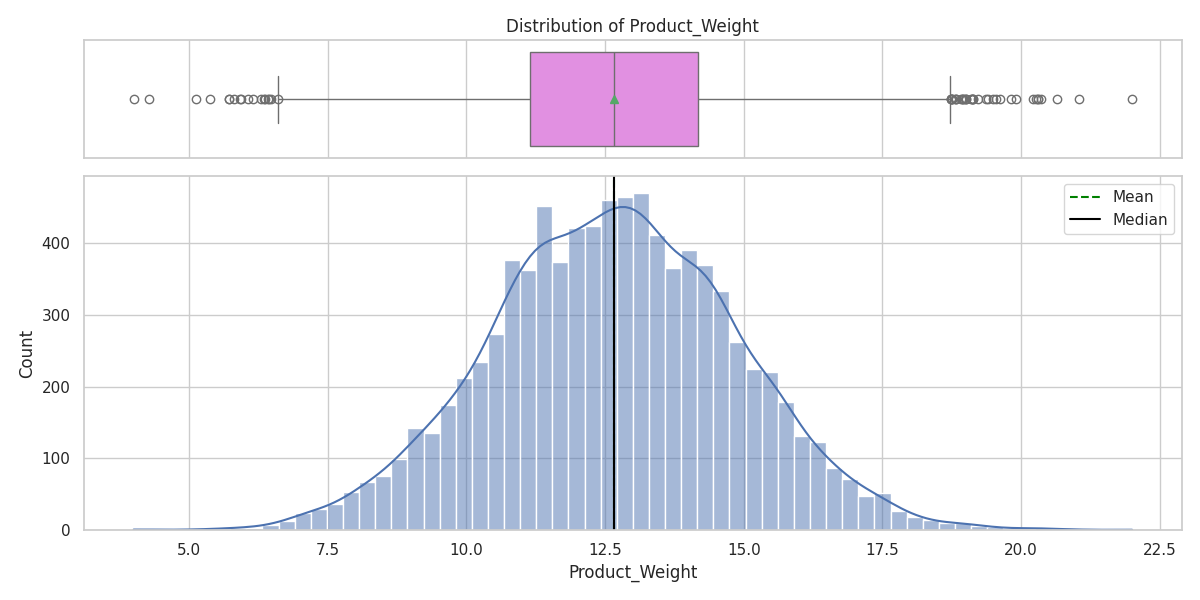

In [16]:
histogram_boxplot(data, "Product_Weight")

**Observations**
- Product_Weight is also roughly normal (mean ≈ 12.65), with a small number of very light and very heavy products outside the whiskers.

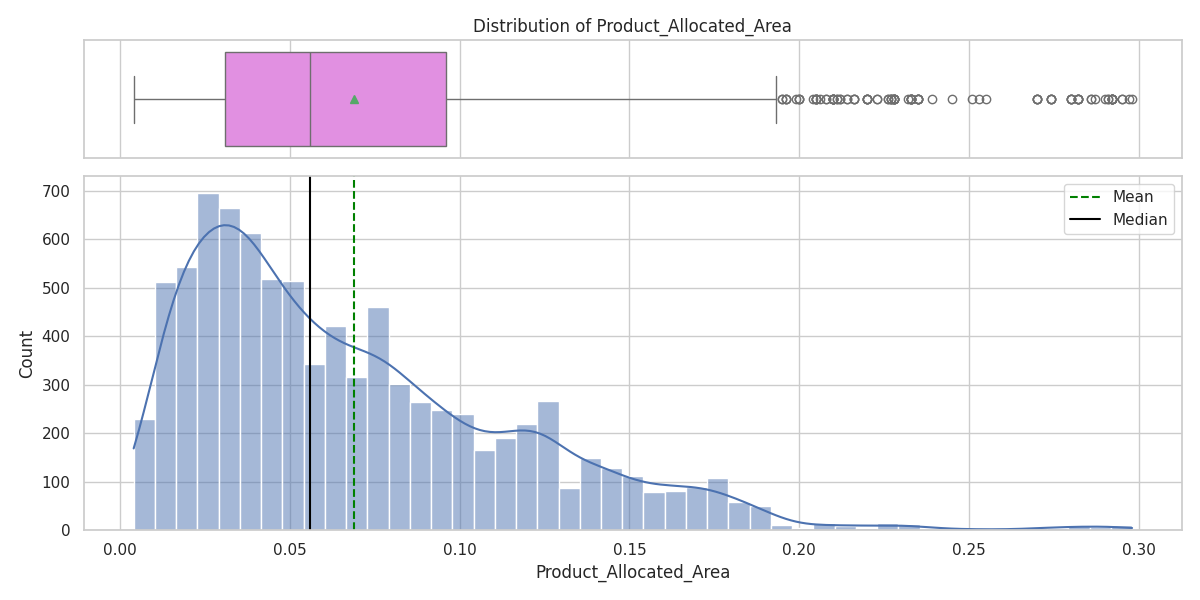

In [17]:
histogram_boxplot(data, "Product_Allocated_Area")

**Observations**
- Product_Allocated_Area is **right-skewed** (skewness ≈ 1.13). Most products get less than 10% of the display area, and a long tail of products gets up to about 30%.
- The tail values are genuine merchandising decisions, so they are kept. Tree-based models are not sensitive to this kind of skew.

### Categorical features

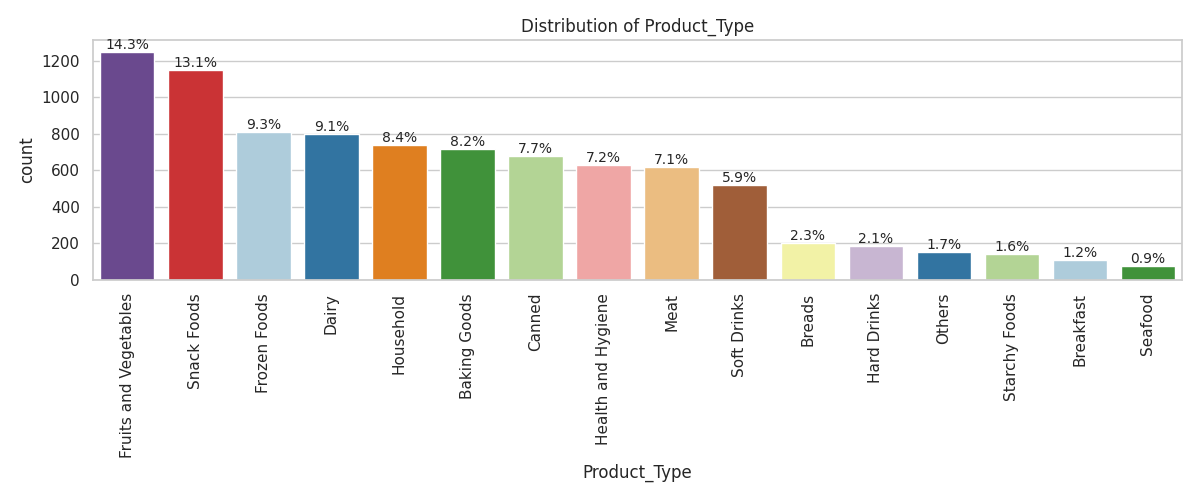

In [18]:
labeled_barplot(data, "Product_Type")

**Observations**
- **Fruits and Vegetables (14.3%)** and **Snack Foods (13.1%)** are the most common product types. Frozen Foods, Dairy, Household and Baking Goods each make up 8–9%.
- Seafood (0.9%), Breakfast (1.2%), Starchy Foods and Others are niche categories.

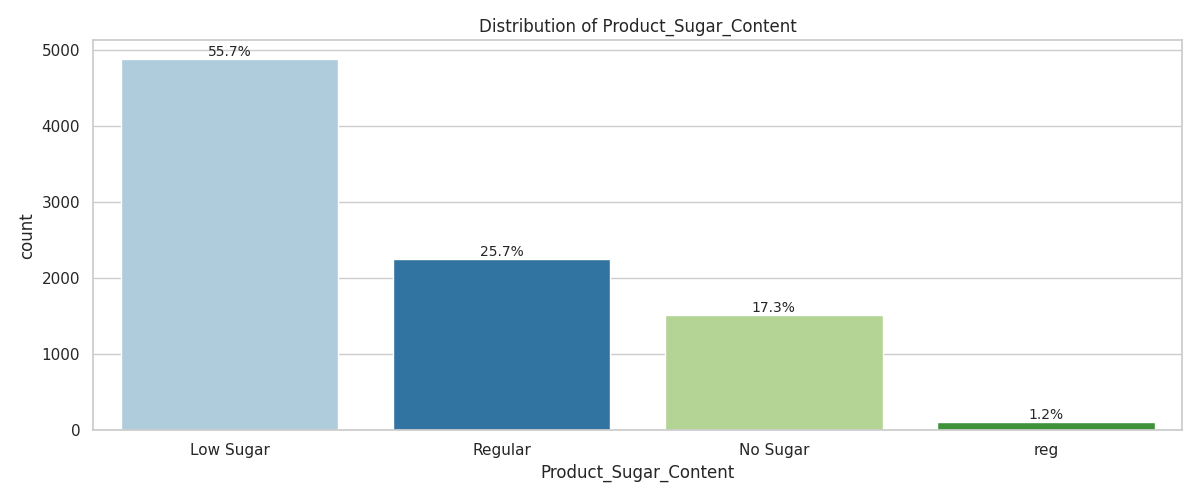

In [19]:
labeled_barplot(data, "Product_Sugar_Content")

**Observations**
- More than half of the products are **Low Sugar (55.7%)**. Regular (25.7%) and No Sugar (17.3%) follow, and `reg` (1.2%) is the duplicate label noted above.

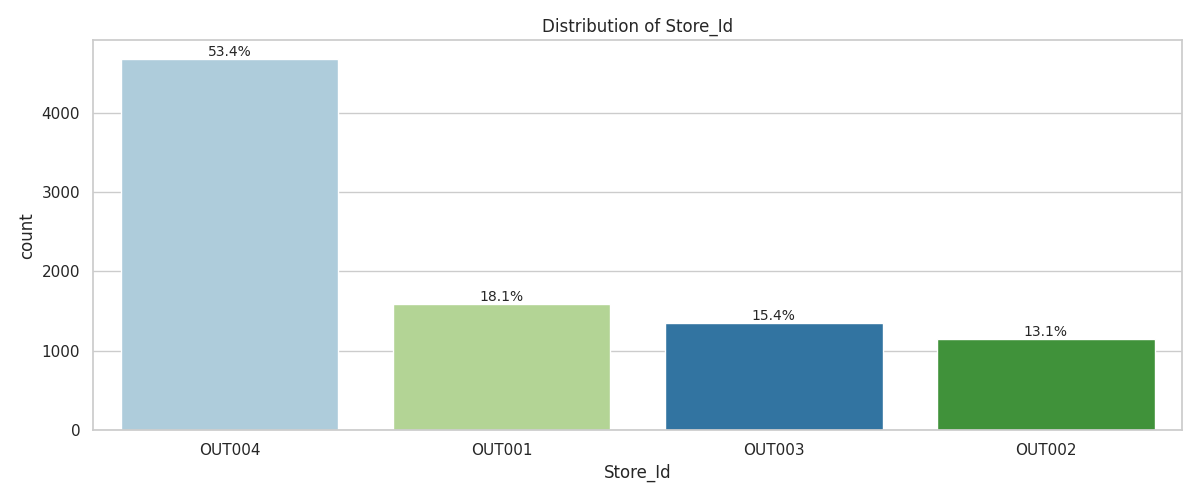

In [20]:
labeled_barplot(data, "Store_Id")

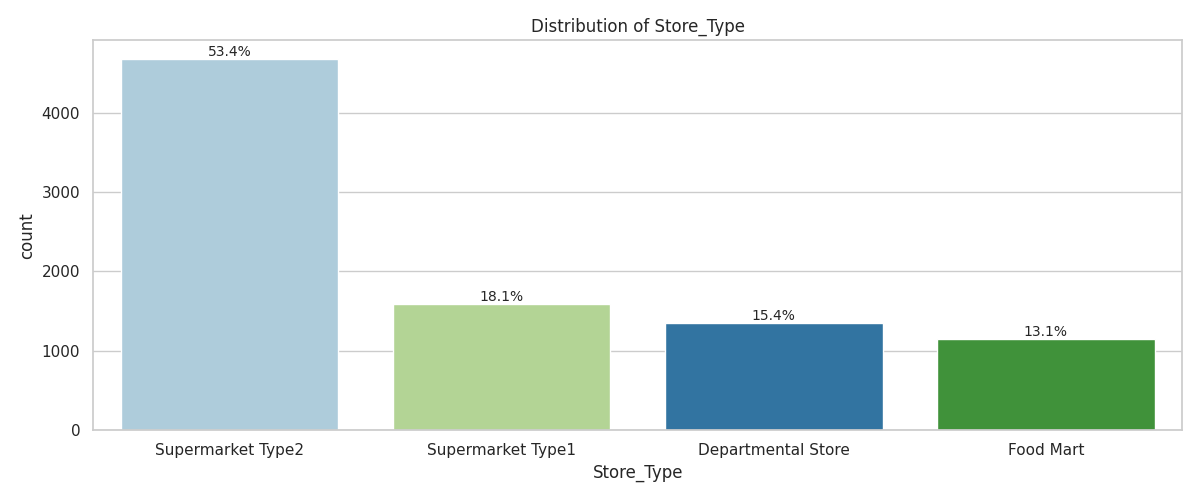

In [21]:
labeled_barplot(data, "Store_Type")

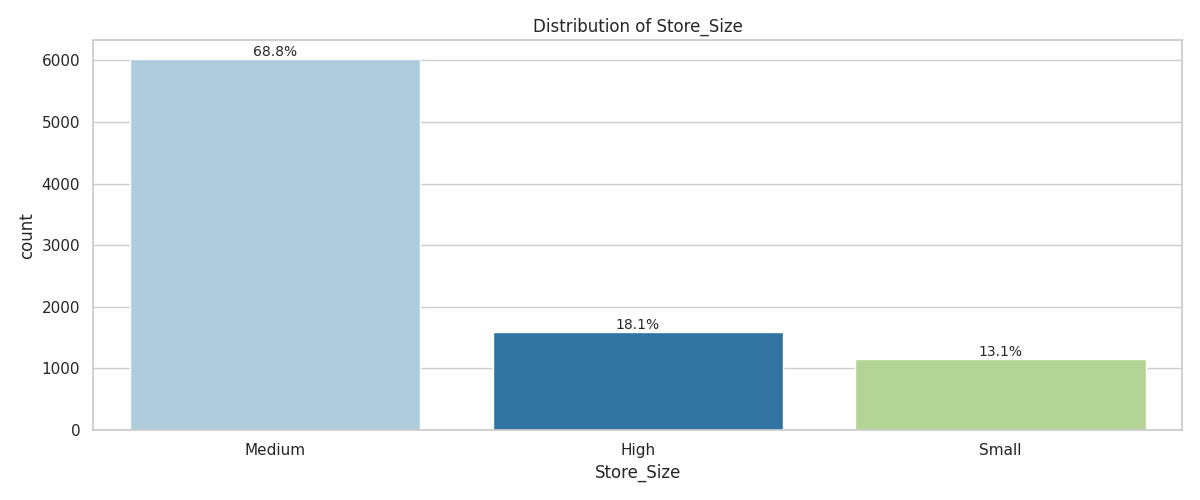

In [22]:
labeled_barplot(data, "Store_Size")

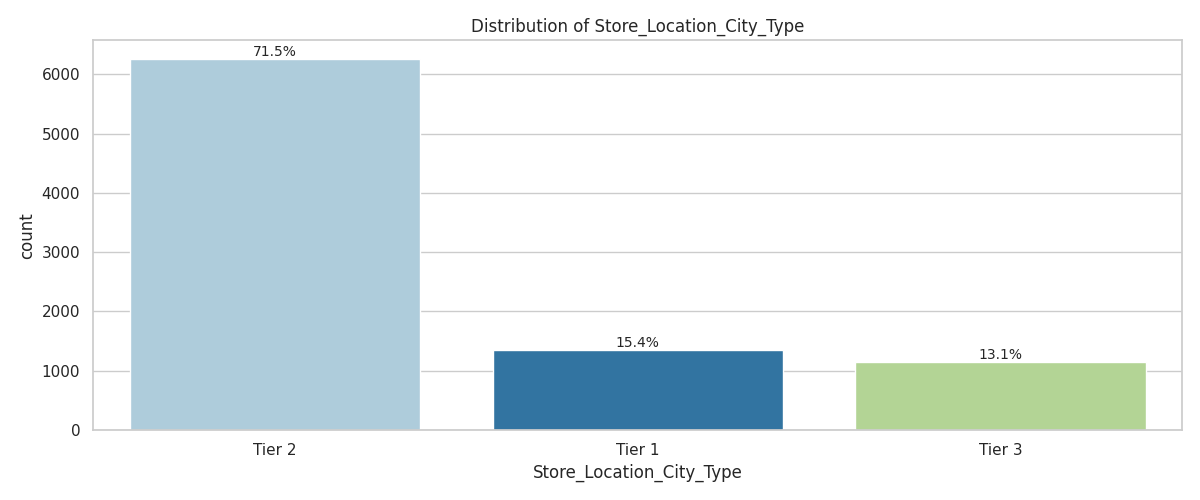

In [23]:
labeled_barplot(data, "Store_Location_City_Type")

**Observations**
- OUT004 (Supermarket Type2) carries 53.4% of the records. OUT001 (18.1%), OUT003 (15.4%) and OUT002 (13.1%) follow.
- The shares are identical across Store_Id, Store_Type, Store_Size and City Tier. For example, 13.1% of rows are Small, Tier 3, Food Mart and OUT002 all at once. This points to a one-to-one mapping between stores and their attributes, which is confirmed below.
- **Medium-size (68.8%)** stores and **Tier 2 (71.5%)** cities dominate the data.

## Bivariate Analysis

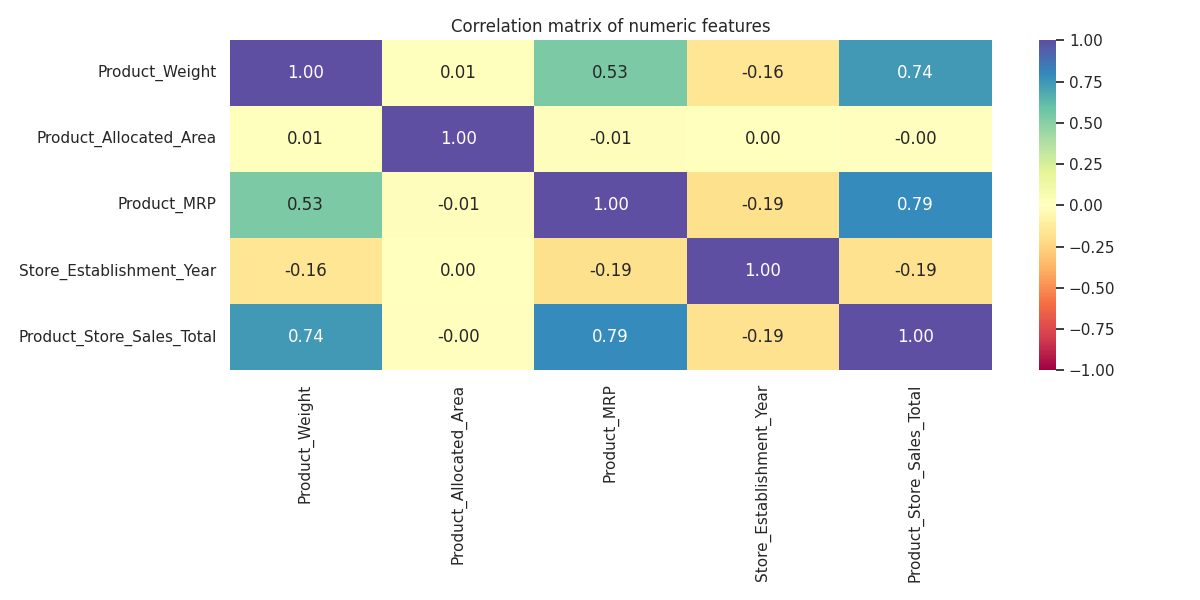

In [24]:
# Correlation between the numeric columns
plt.figure(figsize=(FIG_W, 6))
num_cols = data.select_dtypes(include=np.number).columns
sns.heatmap(data[num_cols].corr(), annot=True, fmt=".2f", cmap="Spectral", vmin=-1, vmax=1)
plt.title("Correlation matrix of numeric features")
plt.tight_layout()
plt.show()

**Observations**
- **Product_MRP (0.79)** and **Product_Weight (0.74)** have the strongest positive correlation with sales. Higher-priced, heavier products generate more revenue per product–store pair.
- MRP and weight are also correlated with each other (0.53), which is expected because larger packs cost more.
- **Product_Allocated_Area has essentially zero linear correlation (-0.00) with sales.** More shelf space is not translating into more revenue.
- Establishment year has a weak negative correlation (-0.19). Because there are only four stores, this mostly reflects store-level differences, which the store variables show more clearly.

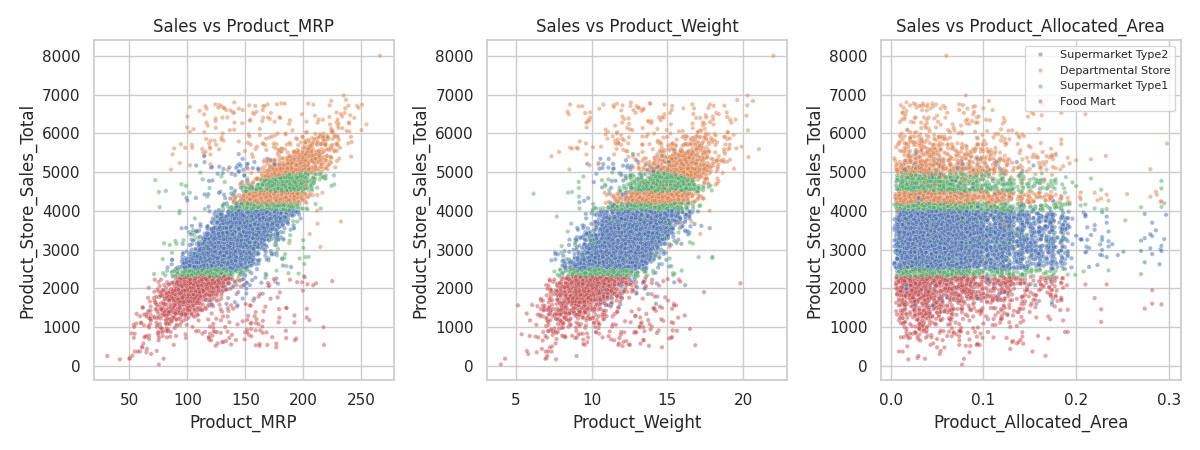

In [25]:
# Sales against each numeric driver
fig, axes = plt.subplots(1, 3, figsize=(FIG_W, 4.5))
for ax, col in zip(axes, ["Product_MRP", "Product_Weight", "Product_Allocated_Area"]):
    sns.scatterplot(data=data, x=col, y="Product_Store_Sales_Total", hue="Store_Type", s=10, alpha=0.5, ax=ax,
                    legend=(col == "Product_Allocated_Area"))
    ax.set_title(f"Sales vs {col}")
axes[2].legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()

**Observations**
- Sales rise almost linearly with MRP, in distinct bands by store type. At any given price, the Departmental Store sits highest and the Food Mart lowest, which shows a strong store effect on top of the price effect.
- Sales also rise with weight.
- The allocated-area plot is a flat cloud, which confirms that display area has no clear relationship with revenue.

In [26]:
# Do the store attributes vary within a store?
for col in ["Store_Type", "Store_Size", "Store_Location_City_Type", "Store_Establishment_Year"]:
    print(pd.crosstab(data["Store_Id"], data[col]), "\n")

Store_Type  Departmental Store  Food Mart  Supermarket Type1  \
Store_Id                                                       
OUT001                       0          0               1586   
OUT002                       0       1152                  0   
OUT003                    1349          0                  0   
OUT004                       0          0                  0   

Store_Type  Supermarket Type2  
Store_Id                       
OUT001                      0  
OUT002                      0  
OUT003                      0  
OUT004                   4676   

Store_Size  High  Medium  Small
Store_Id                       
OUT001      1586       0      0
OUT002         0       0   1152
OUT003         0    1349      0
OUT004         0    4676      0 

Store_Location_City_Type  Tier 1  Tier 2  Tier 3
Store_Id                                        
OUT001                         0    1586       0
OUT002                         0       0    1152
OUT003                      134

**Observations**
- Every store has exactly one type, size, tier and establishment year:

| Store | Type | Size | City Tier | Est. year |
|---|---|---|---|---|
| OUT001 | Supermarket Type1 | High | Tier 2 | 1987 |
| OUT002 | Food Mart | Small | Tier 3 | 1998 |
| OUT003 | Departmental Store | Medium | Tier 1 | 1999 |
| OUT004 | Supermarket Type2 | Medium | Tier 2 | 2009 |

- Store_Id therefore adds no information beyond the store attributes, and it is dropped before modelling. Keeping the descriptive attributes, rather than an ID, lets the model score a new store from its profile.

,,count,mean,sum,revenue_share_%
Store_Id,Store_Type,,,,
OUT004,Supermarket Type2,4676,3299.3,15427583.4,50.8
OUT003,Departmental Store,1349,4947.0,6673457.6,22.0
OUT001,Supermarket Type1,1586,3923.8,6223113.2,20.5
OUT002,Food Mart,1152,1762.9,2030909.7,6.7


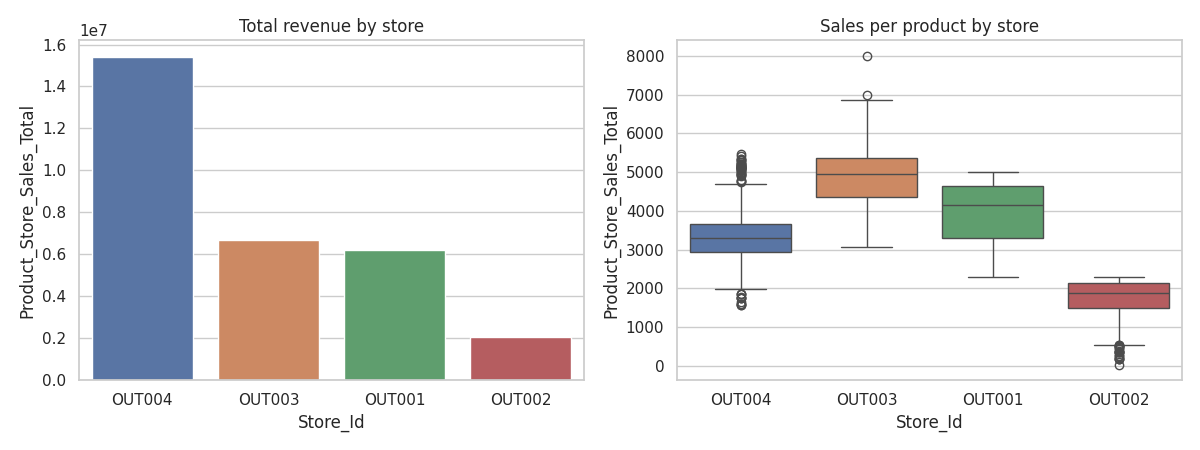

In [27]:
# Revenue contribution and average sales per product by store
store_rev = data.groupby(["Store_Id", "Store_Type"])["Product_Store_Sales_Total"].agg(["count", "mean", "sum"])
store_rev["revenue_share_%"] = 100 * store_rev["sum"] / store_rev["sum"].sum()
display(store_rev.sort_values("sum", ascending=False).round(1))

fig, axes = plt.subplots(1, 2, figsize=(FIG_W, 4.5))
order = store_rev.sort_values("sum", ascending=False).index.get_level_values(0)
sns.barplot(data=data, x="Store_Id", y="Product_Store_Sales_Total", estimator="sum", errorbar=None,
            order=order, ax=axes[0], hue="Store_Id", legend=False)
axes[0].set_title("Total revenue by store")
sns.boxplot(data=data, x="Store_Id", y="Product_Store_Sales_Total", order=order, ax=axes[1], hue="Store_Id", legend=False)
axes[1].set_title("Sales per product by store")
plt.tight_layout()
plt.show()

**Observations**
- **OUT004 (Supermarket Type2) contributes 50.8% of total revenue**, but only because it stocks the most products (4,676). Its average sale per product (≈3,299) is below average.
- **OUT003 (Departmental Store, Tier 1) is the most productive store**. It averages about **4,947 per product**, 50% higher than OUT004, and contributes 22.0% of revenue with only 15.4% of the products.
- OUT001 (Supermarket Type1) averages about 3,924 per product and contributes 20.5% of revenue.
- **OUT002 (Food Mart, Tier 3, Small) averages only about 1,763 per product**, roughly a third of OUT003, and contributes 6.7% of revenue.

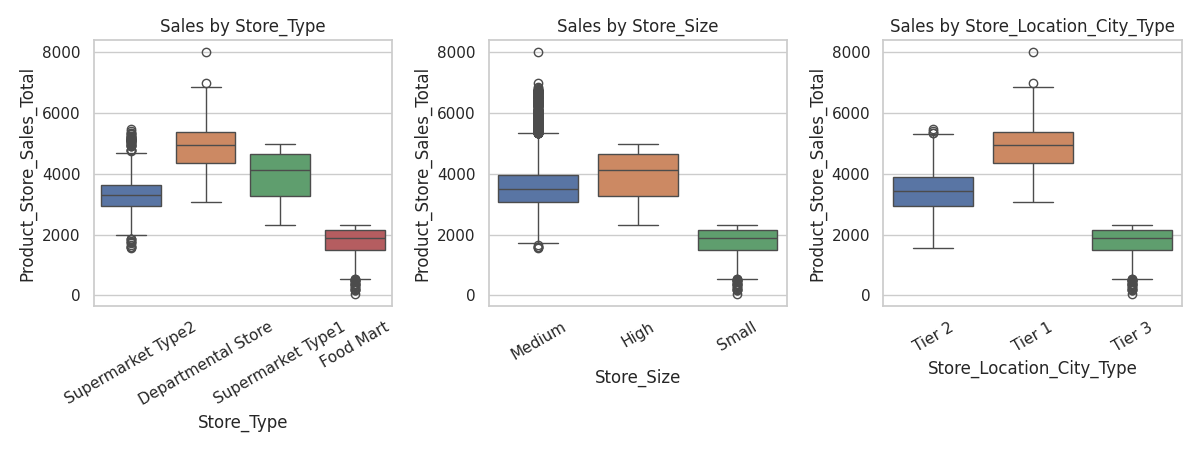

In [28]:
# Sales distribution by the store attributes
fig, axes = plt.subplots(1, 3, figsize=(FIG_W, 4.5))
for ax, col in zip(axes, ["Store_Type", "Store_Size", "Store_Location_City_Type"]):
    sns.boxplot(data=data, x=col, y="Product_Store_Sales_Total", ax=ax, hue=col, legend=False)
    ax.set_title(f"Sales by {col}")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

**Observations**
- Tier 1 cities have the highest sales per product and Tier 3 the lowest. The ranking follows standard of living.
- Store size behaves differently. Medium stores span a wide range because the group mixes the high-performing Departmental Store (OUT003) with Supermarket Type2 (OUT004).
- Store format and location, not size alone, explain the differences.

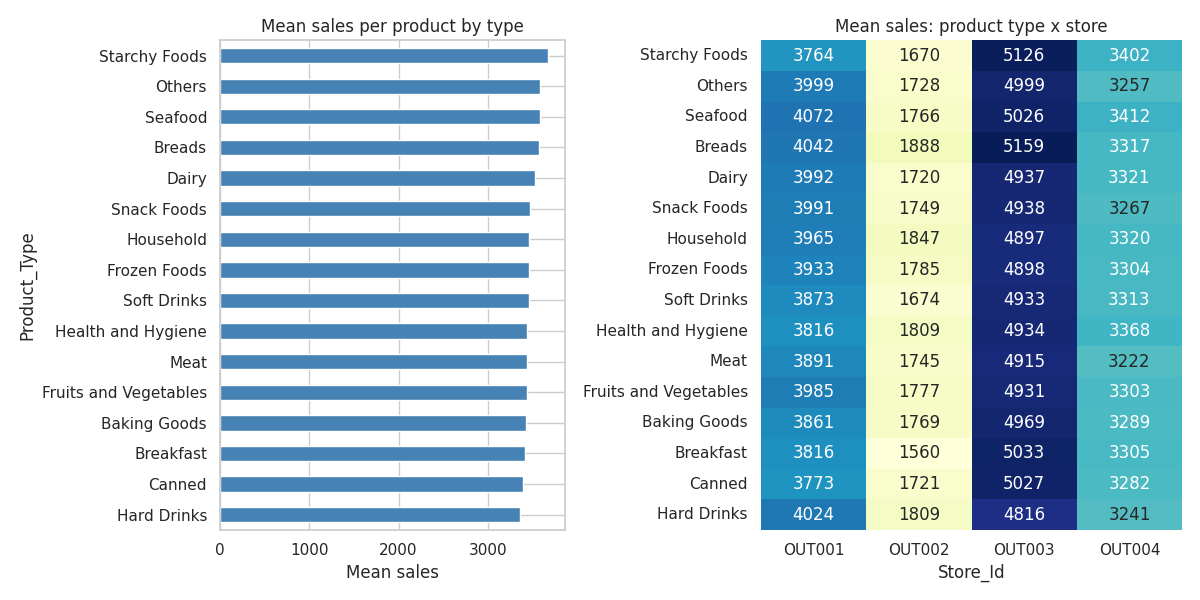

In [29]:
# Product type: average sales per product, and how it varies by store
fig, axes = plt.subplots(1, 2, figsize=(FIG_W, 6), gridspec_kw={"width_ratios": (0.45, 0.55)})
pt = data.groupby("Product_Type")["Product_Store_Sales_Total"].mean().sort_values()
pt.plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set_title("Mean sales per product by type")
axes[0].set_xlabel("Mean sales")
heat = pd.crosstab(data["Product_Type"], data["Store_Id"], values=data["Product_Store_Sales_Total"], aggfunc="mean")
sns.heatmap(heat.loc[pt.index[::-1]], annot=True, fmt=".0f", cmap="YlGnBu", ax=axes[1], cbar=False)
axes[1].set_title("Mean sales: product type x store")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

**Observations**
- Mean sales per product vary little across product types (about 3,365 for Hard Drinks to 3,679 for Starchy Foods, a spread of under 10%).
- In the heatmap the columns differ far more than the rows. **Every product type sells about 4,800–5,200 in OUT003 and about 1,550–1,900 in OUT002.**
- Where a product is sold matters far more than what kind of product it is. A store's performance gap applies across its whole assortment, not just to particular categories.

In [30]:
# Revenue mix by product type within each store (share of store revenue)
mix = pd.crosstab(data["Product_Type"], data["Store_Id"], values=data["Product_Store_Sales_Total"], aggfunc="sum",
                  normalize="columns") * 100
mix.loc[mix.mean(axis=1).sort_values(ascending=False).index].round(1)

Store_Id,OUT001,OUT002,OUT003,OUT004
Product_Type,,,,
Fruits and Vegetables,12.7,14.7,13.4,15.0
Snack Foods,13.0,12.6,13.8,13.0
Dairy,9.6,8.8,10.7,8.5
Frozen Foods,9.0,8.9,9.0,9.6
Household,8.5,9.1,7.9,8.6
Baking Goods,8.4,8.4,7.4,8.2
Meat,8.1,7.5,7.8,6.2
Canned,7.2,7.5,6.8,8.1
Health and Hygiene,7.0,8.1,6.6,7.3


**Observations**
- The revenue mix is similar in all four stores. Fruits and Vegetables and Snack Foods together bring in about a quarter of each store's revenue, and Dairy, Frozen Foods and Household follow.
- These high-volume categories should get priority in procurement and supply-chain planning at every store.

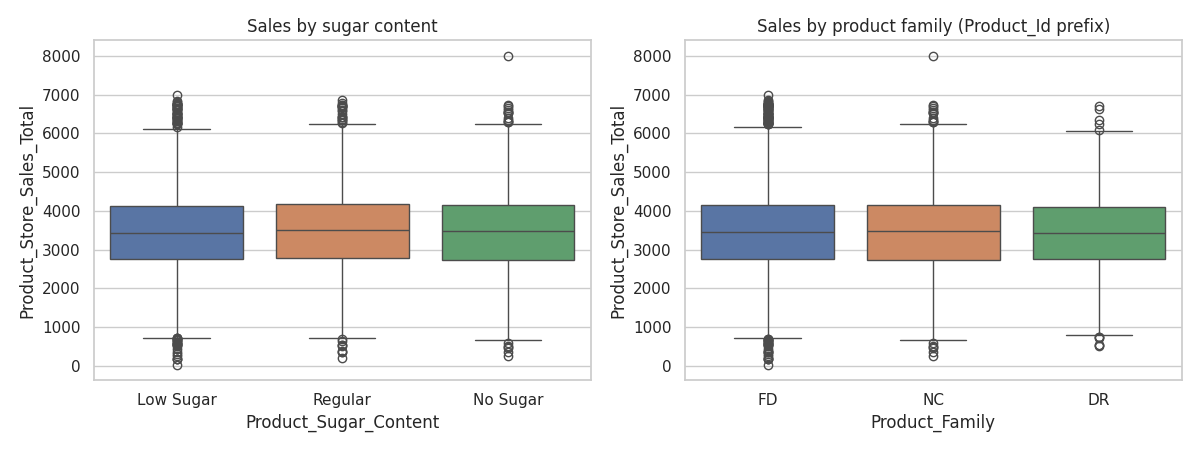

In [31]:
# Sugar content and product family vs sales
fig, axes = plt.subplots(1, 2, figsize=(FIG_W, 4.5))
sns.boxplot(data=data.replace({"Product_Sugar_Content": {"reg": "Regular"}}), x="Product_Sugar_Content",
            y="Product_Store_Sales_Total", ax=axes[0], hue="Product_Sugar_Content", legend=False)
axes[0].set_title("Sales by sugar content")
fam = data.assign(Product_Family=data["Product_Id"].str[:2])
sns.boxplot(data=fam, x="Product_Family", y="Product_Store_Sales_Total", ax=axes[1], hue="Product_Family", legend=False)
axes[1].set_title("Sales by product family (Product_Id prefix)")
plt.tight_layout()
plt.show()

**Observations**
- Sugar content and product family (FD / DR / NC) have nearly identical sales distributions, so on their own they say little about revenue.
- They are still kept as features because a tree model can use them in interactions. The product-family prefix is also part of the API contract that the deployed model must accept.

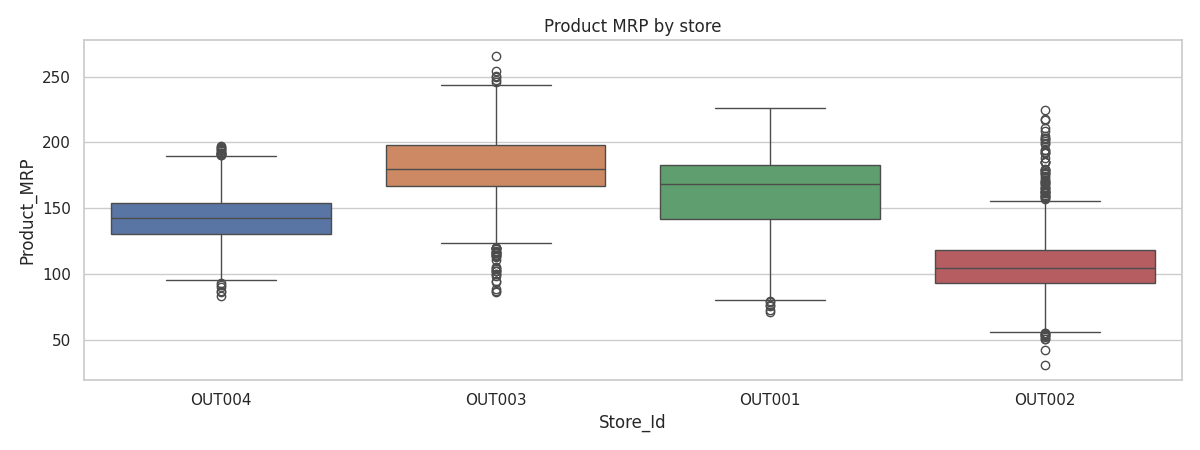

,Product_MRP,Product_Weight
Store_Id,,
OUT001,160.51,13.46
OUT002,107.08,9.91
OUT003,181.36,15.10
OUT004,142.40,12.35


In [32]:
# Product MRP by store - do the stores price their assortment differently?
plt.figure(figsize=(FIG_W, 4.5))
sns.boxplot(data=data, x="Store_Id", y="Product_MRP", order=order, hue="Store_Id", legend=False)
plt.title("Product MRP by store")
plt.tight_layout()
plt.show()
data.groupby("Store_Id")[["Product_MRP", "Product_Weight"]].mean().round(2)

**Observations**
- Each store's assortment is priced differently. **OUT003 stocks the most expensive products (mean MRP ≈ 181)** and **OUT002 the cheapest (≈ 107)**.
- Combined with the strong MRP–sales link, this explains much of the store gap: the Departmental Store sells premium, heavier items, while the Food Mart sells low-price, smaller items.

### EDA summary
1. **Price is the main revenue driver.** MRP (r = 0.79) and weight (r = 0.74) are strongly correlated with sales per product–store pair.
2. **The store sets the revenue level.** Sales per product range from about 1,763 (Food Mart, Tier 3) to about 4,947 (Departmental Store, Tier 1), and this gap holds for every product type.
3. **Display area does not drive revenue** (correlation about 0.00). This is an opportunity to reallocate shelf space.
4. **Each store is a fixed combination of type, size, tier and age**, so Store_Id is dropped and the descriptive attributes are kept.
5. Data-quality fix needed: `reg` → `Regular` in sugar content. Product_Id needs to be reduced to its family prefix.

# **Data Preprocessing**

The feature set is designed to match the schema that the deployed API receives, so the same columns flow from training to serving:

| Engineered feature | Built from | Rationale |
|---|---|---|
| `Product_Id_char` | first two letters of `Product_Id` | turns a unique ID into a product family (FD / DR / NC) |
| `Store_Age_Years` | 2025 − `Store_Establishment_Year` | store age is easier to interpret and reuse than a calendar year (2025 is the reference year of the sales data) |
| `Product_Type_Category` | `Product_Type` | groups 16 types into **Perishables** (Dairy, Meat, Fruits and Vegetables, Breakfast, Breads, Seafood) and **Non Perishables** (everything else, including Frozen Foods, which have a long shelf life) |

In [33]:
# 1. Fix the inconsistent sugar-content label
data["Product_Sugar_Content"] = data["Product_Sugar_Content"].replace("reg", "Regular")
print(data["Product_Sugar_Content"].value_counts(), "\n")

# 2. Product family from the first two characters of Product_Id
data["Product_Id_char"] = data["Product_Id"].str[:2]

# 3. Store age relative to the 2025 reference year of the data
REFERENCE_YEAR = 2025
data["Store_Age_Years"] = REFERENCE_YEAR - data["Store_Establishment_Year"]

# 4. Perishable vs non-perishable product grouping
perishables = ["Dairy", "Meat", "Fruits and Vegetables", "Breakfast", "Breads", "Seafood"]
data["Product_Type_Category"] = np.where(data["Product_Type"].isin(perishables), "Perishables", "Non Perishables")

display(data[["Product_Id", "Product_Id_char", "Store_Establishment_Year", "Store_Age_Years",
              "Product_Type", "Product_Type_Category"]].head())
print(data["Product_Type_Category"].value_counts())

Product_Sugar_Content
Low Sugar    4885
Regular      2359
No Sugar     1519
Name: count, dtype: int64 



,Product_Id,Product_Id_char,Store_Establishment_Year,Store_Age_Years,Product_Type,Product_Type_Category
0,FD6114,FD,2009,16,Frozen Foods,Non Perishables
1,FD7839,FD,1999,26,Dairy,Perishables
2,FD5075,FD,1987,38,Canned,Non Perishables
3,FD8233,FD,1987,38,Baking Goods,Non Perishables
4,NC1180,NC,1998,27,Health and Hygiene,Non Perishables


Product_Type_Category
Non Perishables    5718
Perishables        3045
Name: count, dtype: int64


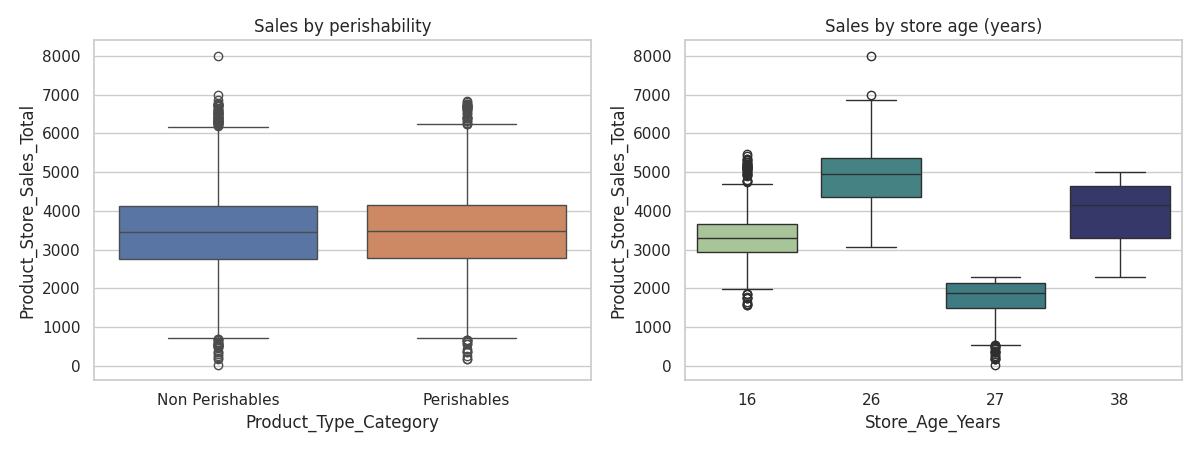

In [34]:
# Engineered features vs the target
fig, axes = plt.subplots(1, 2, figsize=(FIG_W, 4.5))
sns.boxplot(data=data, x="Product_Type_Category", y="Product_Store_Sales_Total", ax=axes[0],
            hue="Product_Type_Category", legend=False)
axes[0].set_title("Sales by perishability")
sns.boxplot(data=data, x="Store_Age_Years", y="Product_Store_Sales_Total", ax=axes[1], hue="Store_Age_Years",
            legend=False, palette="crest")
axes[1].set_title("Sales by store age (years)")
plt.tight_layout()
plt.show()

**Observations**
- Perishables and non-perishables have similar per-product sales. The grouping mainly provides a coarser, more robust signal than 16 sparse product types.
- Store age is not monotonic: the 26-year-old store (OUT003) sells the most and the 27-year-old store (OUT002) the least. Age stands in for each store's format and location rather than having a direct effect.

In [35]:
# Drop the identifiers and the raw columns that the engineered features replace
data = data.drop(columns=["Product_Id", "Store_Id", "Product_Type", "Store_Establishment_Year"])

# Outlier check (IQR rule) - reported, not removed: the extreme values are genuine products/sales
num_features = ["Product_Weight", "Product_Allocated_Area", "Product_MRP", "Product_Store_Sales_Total"]
q1, q3 = data[num_features].quantile(0.25), data[num_features].quantile(0.75)
iqr = q3 - q1
outliers = ((data[num_features] < q1 - 1.5 * iqr) | (data[num_features] > q3 + 1.5 * iqr)).sum()
print("Outliers per column (IQR rule):")
print(outliers)

Outliers per column (IQR rule):
Product_Weight                54
Product_Allocated_Area       104
Product_MRP                   57
Product_Store_Sales_Total    119
dtype: int64


**Observations**
- Each numeric column has only a small number of IQR outliers (54–119 rows, at most 1.4% of the data). They are realistic prices, weights, shelf shares and sales, so they are **kept**. Tree ensembles split on thresholds and are not distorted by extreme values.

In [36]:
# Separate the features and the target
X = data.drop(columns=["Product_Store_Sales_Total"])
y = data["Product_Store_Sales_Total"]

# 80/20 train-test split (fixed random_state for reproducibility)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

print("Training set:", X_train.shape, "| Test set:", X_test.shape)
print("\nFeature columns:", X.columns.tolist())

Training set: (7010, 10) | Test set: (1753, 10)

Feature columns: ['Product_Weight', 'Product_Sugar_Content', 'Product_Allocated_Area', 'Product_MRP', 'Store_Size', 'Store_Location_City_Type', 'Store_Type', 'Product_Id_char', 'Store_Age_Years', 'Product_Type_Category']


In [37]:
# Categorical vs numeric feature lists
categorical_features = X.select_dtypes(include="object").columns.tolist()
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
print("Categorical:", categorical_features)
print("Numeric:    ", numeric_features)

# One-hot encode categoricals; pass numerics through unchanged (tree models do not need scaling).
# handle_unknown="ignore" keeps the API robust when it receives a category not seen during training
# (e.g. a new store type), instead of raising an error.
preprocessor = make_column_transformer(
    (OneHotEncoder(handle_unknown="ignore"), categorical_features),
    remainder="passthrough",
)

Categorical: ['Product_Sugar_Content', 'Store_Size', 'Store_Location_City_Type', 'Store_Type', 'Product_Id_char', 'Product_Type_Category']
Numeric:     ['Product_Weight', 'Product_Allocated_Area', 'Product_MRP', 'Store_Age_Years']


**Preprocessing summary**
- Encoding happens **inside a scikit-learn pipeline**. The serialized model therefore takes raw feature values, exactly as the API receives them, and applies the same encoding at inference time. There is no separate preprocessing step to fall out of sync.
- Numeric features are not scaled because the candidate models are tree ensembles, which are invariant to feature scale.

# **Model Building**

## Define functions for Model Evaluation

In [38]:
# function to compute adjusted R-squared
def adj_r2_score(predictors, targets, predictions):
    r2 = r2_score(targets, predictions)
    n = predictors.shape[0]
    k = predictors.shape[1]
    return 1 - ((1 - r2) * (n - 1) / (n - k - 1))


# function to compute different metrics to check performance of a regression model
def model_performance_regression(model, predictors, target):
    """
    Function to compute different metrics to check regression model performance

    model: regressor
    predictors: independent variables
    target: dependent variable
    """

    # predicting using the independent variables
    pred = model.predict(predictors)

    r2 = r2_score(target, pred)  # to compute R-squared
    adjr2 = adj_r2_score(predictors, target, pred)  # to compute adjusted R-squared
    rmse = np.sqrt(mean_squared_error(target, pred))  # to compute RMSE
    mae = mean_absolute_error(target, pred)  # to compute MAE
    mape = mean_absolute_percentage_error(target, pred)  # to compute MAPE

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {
            "RMSE": rmse,
            "MAE": mae,
            "R-squared": r2,
            "Adj. R-squared": adjr2,
            "MAPE": mape,
        },
        index=[0],
    )

    return df_perf

The ML models to be built can be any two out of the following:
1. Decision Tree
2. Bagging
3. Random Forest
4. AdaBoost
5. Gradient Boosting
6. XGBoost

**Model choice: Random Forest and XGBoost.** Both are ensemble methods that capture the non-linear store × price interactions seen in the EDA. They use opposite strategies, though:
- **Random Forest (bagging)** averages many deep, independent trees to reduce variance.
- **XGBoost (boosting)** builds shallow trees one after another, each correcting the errors of the last, to reduce bias.

**Evaluation metric.** RMSE is the primary metric because it penalises large forecast misses in revenue units. R², MAE and MAPE are reported as supporting measures. Training and test scores are compared to check for overfitting.

### Random Forest Regressor

In [39]:
# Random Forest inside a pipeline with the preprocessor
rf_estimator = make_pipeline(preprocessor, RandomForestRegressor(random_state=RANDOM_STATE))
rf_estimator.fit(X_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('onehotencoder',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Product_Sugar_Content',
                                                   'Store_Size',
                                                   'Store_Location_City_Type',
                                                   'Store_Type',
                                                   'Product_Id_char',
                                                   'Product_Type_Category'])])),
                ('randomforestregressor',
                 RandomForestRegressor(random_state=1))])

In [40]:
rf_estimator_model_train_perf = model_performance_regression(rf_estimator, X_train, y_train)
print("Training performance")
rf_estimator_model_train_perf

Training performance


,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,107.577274,40.161777,0.989765,0.98975,0.015049


In [41]:
rf_estimator_model_test_perf = model_performance_regression(rf_estimator, X_test, y_test)
print("Test performance")
rf_estimator_model_test_perf

Test performance


,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,290.893401,109.999458,0.926592,0.926171,0.038345


**Observations**
- The default Random Forest explains **92.7%** of the variance in test sales (test RMSE ≈ 290.9, MAPE ≈ 3.8%).
- Training R² (0.990) is above test R², and training RMSE (107.6) is much lower than test RMSE. Fully grown trees memorise the training data, so there is **some overfitting**, which tuning should reduce.

### XGBoost Regressor

In [42]:
# XGBoost inside a pipeline with the same preprocessor
xgb_estimator = make_pipeline(preprocessor, XGBRegressor(random_state=RANDOM_STATE))
xgb_estimator.fit(X_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('onehotencoder',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Product_Sugar_Content',
                                                   'Store_Size',
                                                   'Store_Location_City_Type',
                                                   'Store_Type',
                                                   'Product_Id_char',
                                                   'Product_Type_Category'])])),
                ('xgbregressor',
                 XGBRegressor(base_score=None, booster=None, callbacks=None,
                              col...
                              feature_types=None, gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=None,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=None, max_leaves=None,
                              min_child_weight=None, missing=nan,
                              monotone_constraints=None, multi_strategy=None,
                              n_estimators=None, n_jobs=None,
                              num_parallel_tree=None, random_state=1, ...))])

In [43]:
xgb_estimator_model_train_perf = model_performance_regression(xgb_estimator, X_train, y_train)
print("Training performance")
xgb_estimator_model_train_perf

Training performance


,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,134.955206,62.047648,0.983893,0.98387,0.021539


In [44]:
xgb_estimator_model_test_perf = model_performance_regression(xgb_estimator, X_test, y_test)
print("Test performance")
xgb_estimator_model_test_perf

Test performance


,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,300.125764,131.006742,0.921859,0.92141,0.045839


**Observations**
- Default XGBoost reaches test R² **0.922** (RMSE ≈ 300.1, MAPE ≈ 4.6%), slightly behind the default Random Forest.
- There is also a gap between training R² (0.984) and test R². The defaults (6-level trees, learning rate 0.3) fit the training data aggressively.
- Both baselines already explain more than 90% of the variance, which confirms that price and store attributes carry most of the signal.

# **Model Performance Improvement - Hyperparameter Tuning**

Both models are tuned with **GridSearchCV** using 5-fold cross-validation on the training set only. The test set stays unseen until the final comparison. The scoring metric is negative RMSE, matching the primary business metric. The grids target the overfitting seen above:
- **Random Forest:** number of trees, maximum depth, minimum samples per leaf (regularises leaf size) and the share of features considered at each split.
- **XGBoost:** number of trees, tree depth, learning rate, and row and column subsampling.

In [45]:
# 5-fold CV with shuffling, shared by both searches so the CV scores are comparable
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

### Random Forest - tuned

In [46]:
rf_tuned = make_pipeline(preprocessor, RandomForestRegressor(random_state=RANDOM_STATE))

rf_param_grid = {
    "randomforestregressor__n_estimators": [100, 200],
    "randomforestregressor__max_depth": [10, None],
    "randomforestregressor__min_samples_leaf": [1, 3, 5],
    "randomforestregressor__max_features": [0.5, 1.0],
}

rf_grid = GridSearchCV(rf_tuned, rf_param_grid, scoring="neg_root_mean_squared_error", cv=cv, n_jobs=-1)
rf_grid.fit(X_train, y_train)

print("Best parameters:", rf_grid.best_params_)
print(f"Best CV RMSE: {-rf_grid.best_score_:.2f}")

# Refit-on-full-training-set estimator with the best parameters
rf_tuned = rf_grid.best_estimator_

Best parameters: {'randomforestregressor__max_depth': None, 'randomforestregressor__max_features': 1.0, 'randomforestregressor__min_samples_leaf': 3, 'randomforestregressor__n_estimators': 200}
Best CV RMSE: 279.84


In [47]:
rf_tuned_model_train_perf = model_performance_regression(rf_tuned, X_train, y_train)
print("Training performance")
rf_tuned_model_train_perf

Training performance


,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,197.592015,69.901532,0.965471,0.965421,0.026905


In [48]:
rf_tuned_model_test_perf = model_performance_regression(rf_tuned, X_test, y_test)
print("Test performance")
rf_tuned_model_test_perf

Test performance


,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,283.218238,105.805007,0.930415,0.930015,0.036698


**Observations**
- The search selected `n_estimators=200`, `max_depth=None` (fully grown trees), `min_samples_leaf=3` and `max_features=1.0`, with a cross-validated RMSE of 279.8.
- Test RMSE improved from 290.9 to **283.2**, and test R² rose to **0.930**.
- Requiring a minimum number of samples per leaf narrowed the gap between training R² (0.965) and test R². The tuned model generalises better than the default one.

### XGBoost - tuned

In [49]:
xgb_tuned = make_pipeline(preprocessor, XGBRegressor(random_state=RANDOM_STATE))

xgb_param_grid = {
    "xgbregressor__n_estimators": [100, 200, 300],
    "xgbregressor__max_depth": [3, 5, 7],
    "xgbregressor__learning_rate": [0.05, 0.1],
    "xgbregressor__subsample": [0.8, 1.0],
    "xgbregressor__colsample_bytree": [0.8, 1.0],
}

xgb_grid = GridSearchCV(xgb_tuned, xgb_param_grid, scoring="neg_root_mean_squared_error", cv=cv, n_jobs=-1)
xgb_grid.fit(X_train, y_train)

print("Best parameters:", xgb_grid.best_params_)
print(f"Best CV RMSE: {-xgb_grid.best_score_:.2f}")

xgb_tuned = xgb_grid.best_estimator_

Best parameters: {'xgbregressor__colsample_bytree': 1.0, 'xgbregressor__learning_rate': 0.05, 'xgbregressor__max_depth': 7, 'xgbregressor__n_estimators': 100, 'xgbregressor__subsample': 0.8}
Best CV RMSE: 282.19


In [50]:
xgb_tuned_model_train_perf = model_performance_regression(xgb_tuned, X_train, y_train)
print("Training performance")
xgb_tuned_model_train_perf

Training performance


,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,214.48527,81.737735,0.959314,0.959256,0.030341


In [51]:
xgb_tuned_model_test_perf = model_performance_regression(xgb_tuned, X_test, y_test)
print("Test performance")
xgb_tuned_model_test_perf

Test performance


,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,284.807916,109.337851,0.929632,0.929228,0.038493


**Observations**
- The search selected `n_estimators=100`, `max_depth=7`, `learning_rate=0.05`, `subsample=0.8` and `colsample_bytree=1.0`, with a cross-validated RMSE of 282.2.
- Test RMSE improved from 300.1 to **284.8** (R² 0.930, MAPE 3.8%).
- A lower learning rate with row subsampling reduced overfitting: training R² is now 0.959.

# **Model Performance Comparison, Final Model Selection, and Serialization**

In [52]:
# Training performance comparison
models_train_comp_df = pd.concat(
    [rf_estimator_model_train_perf.T, rf_tuned_model_train_perf.T,
     xgb_estimator_model_train_perf.T, xgb_tuned_model_train_perf.T],
    axis=1,
)
models_train_comp_df.columns = ["Random Forest", "Random Forest Tuned", "XGBoost", "XGBoost Tuned"]
print("Training performance comparison:")
models_train_comp_df

Training performance comparison:


,Random Forest,Random Forest Tuned,XGBoost,XGBoost Tuned
RMSE,107.577274,197.592015,134.955206,214.485270
MAE,40.161777,69.901532,62.047648,81.737735
R-squared,0.989765,0.965471,0.983893,0.959314
Adj. R-squared,0.989750,0.965421,0.983870,0.959256
MAPE,0.015049,0.026905,0.021539,0.030341


In [53]:
# Test performance comparison
models_test_comp_df = pd.concat(
    [rf_estimator_model_test_perf.T, rf_tuned_model_test_perf.T,
     xgb_estimator_model_test_perf.T, xgb_tuned_model_test_perf.T],
    axis=1,
)
models_test_comp_df.columns = ["Random Forest", "Random Forest Tuned", "XGBoost", "XGBoost Tuned"]
print("Test performance comparison:")
models_test_comp_df

Test performance comparison:


,Random Forest,Random Forest Tuned,XGBoost,XGBoost Tuned
RMSE,290.893401,283.218238,300.125764,284.807916
MAE,109.999458,105.805007,131.006742,109.337851
R-squared,0.926592,0.930415,0.921859,0.929632
Adj. R-squared,0.926171,0.930015,0.921410,0.929228
MAPE,0.038345,0.036698,0.045839,0.038493


In [54]:
# Generalisation gap (test minus train RMSE) and cross-validated RMSE of the tuned models
gap = (models_test_comp_df.loc["RMSE"] - models_train_comp_df.loc["RMSE"]).rename("RMSE gap (test - train)")
summary = pd.concat([models_test_comp_df.loc[["RMSE", "R-squared", "MAPE"]].T, gap], axis=1)
summary["CV RMSE"] = [np.nan, -rf_grid.best_score_, np.nan, -xgb_grid.best_score_]
summary.round(4)

,RMSE,R-squared,MAPE,RMSE gap (test - train),CV RMSE
Random Forest,290.8934,0.9266,0.0383,183.3161,NaN
Random Forest Tuned,283.2182,0.9304,0.0367,85.6262,279.8447
XGBoost,300.1258,0.9219,0.0458,165.1706,NaN
XGBoost Tuned,284.8079,0.9296,0.0385,70.3226,282.1932


**Model selection**

Tuning improved both models, and the two tuned models end up close. **Random Forest Tuned is selected as the final model** because it is best on every accuracy measure:
- lowest test RMSE: **283.2** vs 284.8 for XGBoost Tuned
- lowest cross-validated RMSE: **279.8** vs 282.2. This confirms that the test-set ranking is not a single-split coincidence.
- highest test R² (**0.930**) and lowest MAPE (**3.67%**) and MAE (**105.8**).

XGBoost Tuned has a slightly smaller train-to-test RMSE gap (70.3 vs 85.6). However, the Random Forest's test and cross-validated errors are both lower, so its larger training fit does not cost accuracy on unseen data. The margin between the two tuned models is small (about 1.6 in RMSE), so XGBoost Tuned would also be a sound production choice.

In [55]:
# Final model
final_model = rf_tuned
final_model_name = "Random Forest Tuned"
print("Final model:", final_model_name)

Final model: Random Forest Tuned


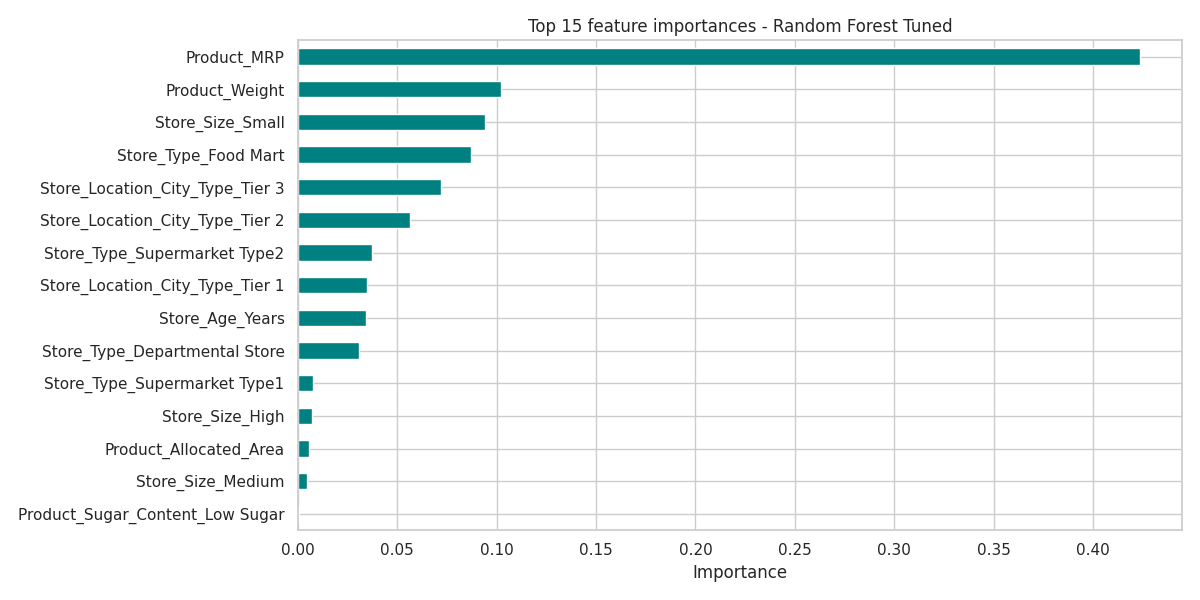

,0
Product_MRP,0.4236
Product_Weight,0.1020
Store_Size_Small,0.0941
Store_Type_Food Mart,0.0872
Store_Location_City_Type_Tier 3,0.0720
Store_Location_City_Type_Tier 2,0.0565
Store_Type_Supermarket Type2,0.0372
Store_Location_City_Type_Tier 1,0.0350
Store_Age_Years,0.0344
Store_Type_Departmental Store,0.0308


In [56]:
# Feature importance of the final model (names recovered from the one-hot encoder)
feature_names = final_model.named_steps["columntransformer"].get_feature_names_out()
feature_names = [f.split("__", 1)[1] for f in feature_names]
importances = pd.Series(final_model[-1].feature_importances_, index=feature_names).sort_values(ascending=False)

plt.figure(figsize=(FIG_W, 6))
importances.head(15).sort_values().plot(kind="barh", color="teal")
plt.title(f"Top 15 feature importances - {final_model_name}")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()
importances.head(10).round(4)

**Observations**
- **Product_MRP is by far the strongest predictor (importance 0.424)**, followed by **Product_Weight (0.102)**.
- Next come the store descriptors: Store_Size_Small (0.094), Store_Type_Food Mart (0.087) and City Tier 3 (0.072). Together these identify the low-revenue Food Mart, OUT002. Tier 2 / Tier 1, Supermarket Type2 and store age then distinguish the other three outlets.
- This matches the EDA: the product's price point combined with the store it is sold in drives the revenue forecast. Sugar content, perishability and product family have small importances.

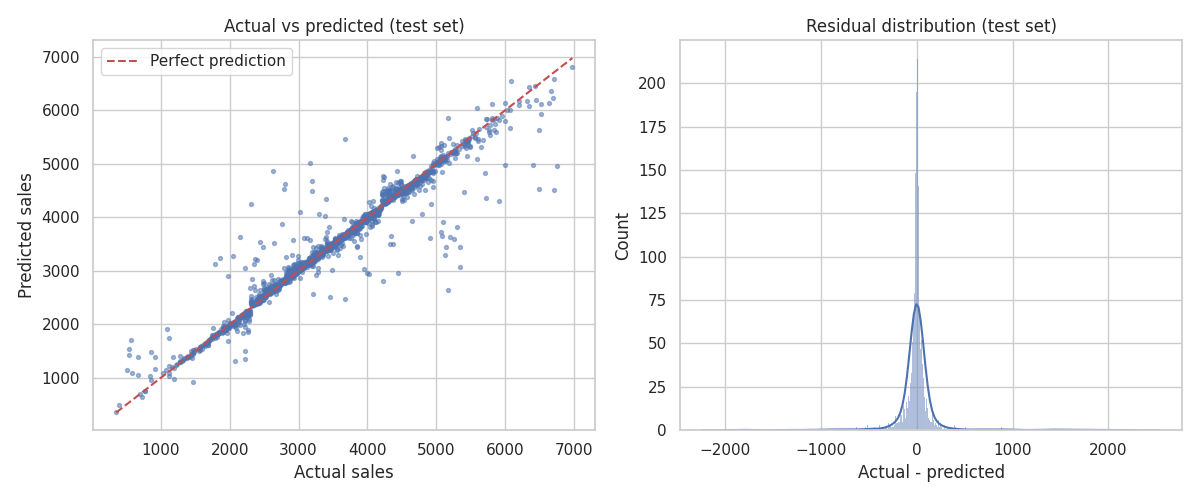

Mean residual: 2.67 | Residual std: 283.29


In [57]:
# Actual vs predicted and residuals on the test set
y_pred = final_model.predict(X_test)
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(FIG_W, 5))
axes[0].scatter(y_test, y_pred, s=8, alpha=0.5)
lims = [y_test.min(), y_test.max()]
axes[0].plot(lims, lims, "r--", label="Perfect prediction")
axes[0].set_xlabel("Actual sales")
axes[0].set_ylabel("Predicted sales")
axes[0].set_title("Actual vs predicted (test set)")
axes[0].legend()
sns.histplot(residuals, kde=True, ax=axes[1])
axes[1].set_title("Residual distribution (test set)")
axes[1].set_xlabel("Actual - predicted")
plt.tight_layout()
plt.show()
print(f"Mean residual: {residuals.mean():.2f} | Residual std: {residuals.std():.2f}")

**Observations**
- Predictions lie tightly along the diagonal across the whole sales range. Residuals are centred on zero (mean 2.67) and roughly symmetric, so the model does not systematically over- or under-forecast.
- The largest errors are at the extremes of the sales range (very low and very high totals), where there are fewest training examples.

### Serialization
The final pipeline, encoder and model together, is saved with `joblib` into `backend_files/`, the folder that becomes the Flask backend's Docker build context.

In [58]:
# Folder for the backend deployment files
os.makedirs("backend_files", exist_ok=True)

saved_model_path = "backend_files/superkart_model.joblib"
# compress=3 shrinks the file roughly 3x (easier to push to GitHub); loading is unchanged
joblib.dump(final_model, saved_model_path, compress=3)
print(f"Model saved to {saved_model_path} ({os.path.getsize(saved_model_path) / 1e6:.2f} MB)")

Model saved to backend_files/superkart_model.joblib (11.05 MB)


In [59]:
# Reload the serialized model and confirm it reproduces the in-memory predictions exactly
saved_model = joblib.load(saved_model_path)
print(saved_model)
assert np.allclose(saved_model.predict(X_test), final_model.predict(X_test))
print("\nReloaded model reproduces the original predictions on the test set.")

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('onehotencoder',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Product_Sugar_Content',
                                                   'Store_Size',
                                                   'Store_Location_City_Type',
                                                   'Store_Type',
                                                   'Product_Id_char',
                                                   'Product_Type_Category'])])),
                ('randomforestregressor',
                 RandomForestRegressor(min_samples_leaf=3, n_estimators=200,
                                       random_state=1))])

Reloaded model reproduces the original predictions on the test set.


In [60]:
# Score one raw record in the exact API format, using the reloaded model
sample = pd.DataFrame([{
    "Product_Weight": 12.66, "Product_Sugar_Content": "Low Sugar", "Product_Allocated_Area": 0.027,
    "Product_MRP": 117.08, "Store_Size": "Medium", "Store_Location_City_Type": "Tier 2",
    "Store_Type": "Supermarket Type2", "Product_Id_char": "FD", "Store_Age_Years": 16,
    "Product_Type_Category": "Non Perishables",
}])
print(f"Predicted sales for the sample record: {saved_model.predict(sample)[0]:,.2f}")

Predicted sales for the sample record: 2,910.00


# **Deployment - Backend**

## Points to note before executing the below cells
- Create a GitHub account if you don't already have one at [github.com](https://github.com)
- Generate a **Personal Access Token**
  - Make sure the token has **repo** scope (full control of private repositories)
- The serialized ML model file (`superkart_model.joblib`) should already be present in the `backend_files` folder before pushing to GitHub
- We will deploy **both the Flask backend and the Streamlit frontend as separate Docker containers** inside a GitHub Codespace, and connect them using a **Docker network**

## Flask Web Framework

Flask is a lightweight, flexible Python web framework used to build web applications and APIs quickly and easily.

Flask allows you to:
- Create web routes (URLs that users can access)
- Handle HTTP requests and responses
- Build REST APIs to expose machine learning models or other services

In [61]:
# Folder layout for the deployment repository
os.makedirs("backend_files", exist_ok=True)
os.makedirs("frontend_files", exist_ok=True)

In [62]:
%%writefile backend_files/app.py
import os

import joblib
import pandas as pd
from flask import Flask, jsonify, request

# Initialise the Flask app
superkart_api = Flask("SuperKart Sales Forecast API")

# Load the serialized pipeline once at start-up (it sits next to this file)
MODEL_PATH = os.path.join(os.path.dirname(os.path.abspath(__file__)), "superkart_model.joblib")
model = joblib.load(MODEL_PATH)

# Features the model expects, in training order
FEATURES = [
    "Product_Weight", "Product_Sugar_Content", "Product_Allocated_Area", "Product_MRP",
    "Store_Size", "Store_Location_City_Type", "Store_Type",
    "Product_Id_char", "Store_Age_Years", "Product_Type_Category",
]
NUMERIC = ["Product_Weight", "Product_Allocated_Area", "Product_MRP", "Store_Age_Years"]


def to_frame(records):
    """Turn a list of dicts into a model-ready DataFrame with numeric columns cast to float."""
    df = pd.DataFrame(records)[FEATURES]
    df[NUMERIC] = df[NUMERIC].astype(float)
    return df


@superkart_api.get("/")
def home():
    """Health check."""
    return "Welcome to the SuperKart Sales Forecast API"


@superkart_api.post("/v1/predict")
def predict_sales():
    """Online inference: one JSON record in, one sales forecast out."""
    data = request.get_json(silent=True)
    if not isinstance(data, dict):
        return jsonify({"error": "Request body must be a JSON object"}), 400
    missing = [f for f in FEATURES if f not in data]
    if missing:
        return jsonify({"error": f"Missing fields: {missing}"}), 400
    try:
        prediction = float(model.predict(to_frame([data]))[0])
    except (ValueError, TypeError) as exc:
        return jsonify({"error": f"Invalid input: {exc}"}), 400
    return jsonify({"Predicted Sales": round(prediction, 2)})


@superkart_api.post("/v1/predictbatch")
def predict_sales_batch():
    """Batch inference: CSV file (form field 'file') in, {row index: forecast} out."""
    if "file" not in request.files:
        return jsonify({"error": "Upload a CSV file in the 'file' form field"}), 400
    batch = pd.read_csv(request.files["file"])
    missing = [f for f in FEATURES if f not in batch.columns]
    if missing:
        return jsonify({"error": f"Missing columns: {missing}"}), 400
    try:
        predictions = model.predict(to_frame(batch.to_dict(orient="records")))
    except (ValueError, TypeError) as exc:
        return jsonify({"error": f"Invalid input: {exc}"}), 400
    return jsonify({str(idx): round(float(p), 2) for idx, p in zip(batch.index, predictions)})


if __name__ == "__main__":
    superkart_api.run(host="0.0.0.0", port=7860, debug=False)

Writing backend_files/app.py


**Backend API design**
- `GET /` is a health check that confirms the service is up.
- `POST /v1/predict` is **online inference**. It accepts one JSON record, validates that all 10 features are present, and returns the predicted sales.
- `POST /v1/predictbatch` is **batch inference**. It accepts a CSV file in the `file` form field and returns a JSON object of `{row index: predicted sales}`.
- The model is loaded **once at start-up** rather than on every request. Invalid input returns HTTP 400 with an explanation instead of a server error.

## Dependencies File

In [63]:
%%writefile backend_files/requirements.txt
pandas==2.2.3
numpy==2.1.3
scikit-learn==1.6.1
xgboost==2.1.4
joblib==1.4.2
flask==3.0.3
gunicorn==23.0.0

Writing backend_files/requirements.txt


The library versions are pinned to the ones used to train and serialize the model. A joblib file must be loaded with the same scikit-learn and XGBoost versions to be safe.

## Dockerfile

In [64]:
%%writefile backend_files/Dockerfile
# Lightweight Python base image
FROM python:3.12-slim

# OpenMP runtime used by XGBoost / scikit-learn
RUN apt-get update && apt-get install -y --no-install-recommends libgomp1 && rm -rf /var/lib/apt/lists/*

WORKDIR /app

# Install dependencies first so this layer is cached between code changes
COPY requirements.txt .
RUN pip install --no-cache-dir --upgrade -r requirements.txt

# Copy the Flask app and the serialized model
COPY . .

EXPOSE 7860

# Serve the Flask app with gunicorn (production WSGI server): 2 workers on port 7860
CMD ["gunicorn", "-w", "2", "-b", "0.0.0.0:7860", "--timeout", "120", "app:superkart_api"]

Writing backend_files/Dockerfile


### Local test of the backend before deployment
Before pushing to GitHub, the Flask app is loaded in-process and called through Flask's test client. This confirms that both endpoints work with the serialized model and catches errors before any container is built.

In [65]:
import importlib.util

# Load backend_files/app.py as a module (it reads the model from its own folder)
spec = importlib.util.spec_from_file_location("superkart_backend", "backend_files/app.py")
backend = importlib.util.module_from_spec(spec)
spec.loader.exec_module(backend)
client = backend.superkart_api.test_client()

print("GET /                ->", client.get("/").status_code, client.get("/").get_data(as_text=True))

r = client.post("/v1/predict", json=sample.iloc[0].to_dict())
print("POST /v1/predict      ->", r.status_code, r.get_json())

r = client.post("/v1/predict", json={"Product_MRP": 100})
print("POST /v1/predict (bad)->", r.status_code, r.get_json())

with open("Batch_Data_SuperKart.csv", "rb") as f:
    r = client.post("/v1/predictbatch", data={"file": (f, "batch.csv")}, content_type="multipart/form-data")
print("POST /v1/predictbatch ->", r.status_code, r.get_json())

GET /                -> 200 Welcome to the SuperKart Sales Forecast API
POST /v1/predict      -> 200 {'Predicted Sales': 2910.0}
POST /v1/predict (bad)-> 400 {'error': "Missing fields: ['Product_Weight', 'Product_Sugar_Content', 'Product_Allocated_Area', 'Store_Size', 'Store_Location_City_Type', 'Store_Type', 'Product_Id_char', 'Store_Age_Years', 'Product_Type_Category']"}
POST /v1/predictbatch -> 200 {'0': 4104.14, '1': 3325.86, '2': 4167.32, '3': 1846.48, '4': 4143.08, '5': 5165.83, '6': 2629.71, '7': 2393.14, '8': 4541.27, '9': 2358.25}


**Observations**
- All three paths behave as intended: a healthy root, a valid single prediction, a clear 400 error for an incomplete payload, and predictions for all 10 batch rows.
- The batch file includes categories never seen in training (`Supermarket Type3`, `Small` paired with Tier 1). The `handle_unknown="ignore"` encoder scores them without failing.

# **Deployment - Frontend**

## Streamlit for Interactive UI

In [66]:
%%writefile frontend_files/app.py
import os

import pandas as pd
import requests
import streamlit as st

# Backend address: the backend container's name on the shared Docker network
BACKEND_URL = os.getenv("BACKEND_URL", "http://superkart-backend:7860").rstrip("/")

st.set_page_config(page_title="SuperKart Sales Forecast", page_icon="🛒", layout="centered")
st.title("SuperKart Sales Forecast")
st.caption("Forecast the sales revenue of a product in a SuperKart outlet for the upcoming quarter.")

single_tab, batch_tab = st.tabs(["Single forecast", "Batch forecast"])

with single_tab:
    st.subheader("Product details")
    col1, col2 = st.columns(2)
    with col1:
        product_id_char = st.selectbox("Product family (Product_Id prefix)", ["FD", "DR", "NC"],
                                       help="FD = food, DR = drinks, NC = non-consumables")
        product_type_category = st.selectbox("Product category", ["Perishables", "Non Perishables"])
        sugar = st.selectbox("Sugar content", ["Low Sugar", "Regular", "No Sugar"])
    with col2:
        mrp = st.number_input("Product MRP", min_value=1.0, max_value=500.0, value=147.0, step=1.0)
        weight = st.number_input("Product weight", min_value=1.0, max_value=50.0, value=12.65, step=0.1)
        area = st.number_input("Allocated display area (ratio)", min_value=0.001, max_value=1.0,
                               value=0.068, step=0.001, format="%.3f")

    st.subheader("Store details")
    col3, col4 = st.columns(2)
    with col3:
        store_type = st.selectbox("Store type", ["Supermarket Type1", "Supermarket Type2",
                                                 "Departmental Store", "Food Mart"])
        store_size = st.selectbox("Store size", ["Small", "Medium", "High"], index=1)
    with col4:
        city_tier = st.selectbox("City tier", ["Tier 1", "Tier 2", "Tier 3"], index=1)
        store_age = st.number_input("Store age (years)", min_value=0, max_value=100, value=16, step=1)

    payload = {
        "Product_Weight": weight,
        "Product_Sugar_Content": sugar,
        "Product_Allocated_Area": area,
        "Product_MRP": mrp,
        "Store_Size": store_size,
        "Store_Location_City_Type": city_tier,
        "Store_Type": store_type,
        "Product_Id_char": product_id_char,
        "Store_Age_Years": store_age,
        "Product_Type_Category": product_type_category,
    }

    if st.button("Predict sales", type="primary"):
        try:
            resp = requests.post(f"{BACKEND_URL}/v1/predict", json=payload, timeout=30)
            if resp.ok:
                st.success("Forecast ready")
                st.metric("Predicted product-store sales", f"{resp.json()['Predicted Sales']:,.2f}")
            else:
                st.error(f"API error {resp.status_code}: {resp.text}")
        except requests.exceptions.RequestException as exc:
            st.error(f"Could not reach the forecasting API at {BACKEND_URL}: {exc}")

with batch_tab:
    st.write("Upload a CSV with the columns: `" + "`, `".join(payload.keys()) + "`.")
    uploaded = st.file_uploader("Batch CSV", type="csv")
    if uploaded is not None:
        batch_df = pd.read_csv(uploaded)
        st.dataframe(batch_df.head(), use_container_width=True)
        if st.button("Predict batch", type="primary"):
            try:
                resp = requests.post(f"{BACKEND_URL}/v1/predictbatch",
                                     files={"file": batch_df.to_csv(index=False).encode("utf-8")}, timeout=120)
                if resp.ok:
                    preds = pd.Series(resp.json(), name="Predicted_Sales")
                    preds.index = preds.index.astype(int)
                    result = batch_df.join(preds.sort_index())
                    st.dataframe(result, use_container_width=True)
                    st.metric("Total forecast revenue", f"{result['Predicted_Sales'].sum():,.2f}")
                    st.download_button("Download forecasts", result.to_csv(index=False),
                                       file_name="superkart_forecasts.csv", mime="text/csv")
                else:
                    st.error(f"API error {resp.status_code}: {resp.text}")
            except requests.exceptions.RequestException as exc:
                st.error(f"Could not reach the forecasting API at {BACKEND_URL}: {exc}")

Writing frontend_files/app.py


**Frontend design**
- **Single forecast tab:** store managers or planners enter a product's attributes and the store profile and get an instant sales forecast.
- **Batch forecast tab:** upload a CSV, for example next quarter's planned assortment, and download it back with a `Predicted_Sales` column.
- The frontend has no model of its own. It calls the backend API, whose address comes from the `BACKEND_URL` environment variable (the backend container's name on the shared Docker network). Either side can be updated or scaled independently.

## Dependencies File

In [67]:
%%writefile frontend_files/requirements.txt
pandas==2.2.3
requests==2.32.4
streamlit==1.43.2

Writing frontend_files/requirements.txt


## Dockerfile

In [68]:
%%writefile frontend_files/Dockerfile
FROM python:3.12-slim

WORKDIR /app

COPY requirements.txt .
RUN pip install --no-cache-dir --upgrade -r requirements.txt

COPY . .

EXPOSE 8501

# Address of the backend container on the shared Docker network (overridable at run time)
ENV BACKEND_URL=http://superkart-backend:7860

CMD ["streamlit", "run", "app.py", "--server.port=8501", "--server.address=0.0.0.0", "--server.enableXsrfProtection=false"]

Writing frontend_files/Dockerfile


### Container orchestration script
This script builds both images and starts them on a shared Docker network, `superkart-net`, inside the Codespace. On that network the frontend reaches the backend by container name (`http://superkart-backend:7860`). Port 7860 (API) and port 8501 (UI) are forwarded by the Codespace.

In [69]:
%%writefile run_containers.sh
#!/usr/bin/env bash
# Build and run the SuperKart backend + frontend containers on a shared Docker network
set -e

docker network create superkart-net 2>/dev/null || echo "Network superkart-net already exists"
docker rm -f superkart-backend superkart-frontend 2>/dev/null || true

docker build -t superkart-backend ./backend_files
docker build -t superkart-frontend ./frontend_files

docker run -d --name superkart-backend  --network superkart-net -p 7860:7860 superkart-backend
docker run -d --name superkart-frontend --network superkart-net -p 8501:8501 \
  -e BACKEND_URL=http://superkart-backend:7860 superkart-frontend

docker ps
echo "Backend API : port 7860  |  Streamlit UI : port 8501  (see the Ports tab)"

Writing run_containers.sh


# **Pushing Deployment Files to GitHub**

The deployment files are pushed to a GitHub repository through the GitHub REST API. The Personal Access Token is read from Colab's **Secrets** panel (key `GITHUB_TOKEN`), or entered at a hidden prompt, so it never appears in the notebook or its output.

In [70]:
import base64
import getpass

GITHUB_USERNAME = "adkanoop-design"        # GitHub account that owns the repository
REPO_NAME = "superkart-sales-forecast"     # repository holding the deployment files

# Read the token from Colab Secrets, falling back to a hidden prompt
try:
    from google.colab import userdata
    GITHUB_TOKEN = userdata.get("GITHUB_TOKEN")
except Exception:
    GITHUB_TOKEN = getpass.getpass("GitHub Personal Access Token: ")

headers = {"Authorization": f"token {GITHUB_TOKEN}", "Accept": "application/vnd.github+json"}
repo_api = f"https://api.github.com/repos/{GITHUB_USERNAME}/{REPO_NAME}"

# Create the repository if it does not exist yet
if requests.get(repo_api, headers=headers).status_code == 404:
    r = requests.post("https://api.github.com/user/repos", headers=headers,
                      json={"name": REPO_NAME, "private": False,
                            "description": "SuperKart sales forecasting - Flask API + Streamlit UI in Docker"})
    print("Repository created" if r.status_code == 201 else f"Repository creation failed: {r.status_code} {r.text}")
else:
    print("Repository already exists")


def upload_file(local_path, repo_path):
    """Create or update one file in the repository through the GitHub contents API."""
    with open(local_path, "rb") as f:
        content = base64.b64encode(f.read()).decode("utf-8")
    url = f"{repo_api}/contents/{repo_path}"
    body = {"message": f"Add/update {repo_path}", "content": content}
    existing = requests.get(url, headers=headers)
    if existing.status_code == 200:          # file already present -> include its sha to update it
        body["sha"] = existing.json()["sha"]
    resp = requests.put(url, headers=headers, json=body)
    print(f"{repo_path:40s} -> {'OK' if resp.status_code in (200, 201) else resp.status_code}")


for folder in ["backend_files", "frontend_files"]:
    for file_name in sorted(os.listdir(folder)):
        if os.path.isfile(os.path.join(folder, file_name)):
            upload_file(os.path.join(folder, file_name), f"{folder}/{file_name}")
upload_file("run_containers.sh", "run_containers.sh")

print(f"\nRepository: https://github.com/{GITHUB_USERNAME}/{REPO_NAME}")

Repository created
backend_files/Dockerfile                 -> OK
backend_files/app.py                     -> OK
backend_files/requirements.txt           -> OK
backend_files/superkart_model.joblib     -> OK
frontend_files/Dockerfile                -> OK
frontend_files/app.py                    -> OK
frontend_files/requirements.txt          -> OK
run_containers.sh                        -> OK

Repository: https://github.com/adkanoop-design/superkart-sales-forecast


### Launching the containers in a GitHub Codespace
1. Open the repository on GitHub → **Code → Codespaces → Create codespace on main**.
2. In the Codespace terminal, run `bash run_containers.sh`. This builds both images, creates the `superkart-net` network and starts both containers.
3. In the **Ports** tab, set port **7860** to **Public** and copy its forwarded URL for the inference cells below. Opening port **8501** shows the Streamlit UI.

# **Inferencing using Flask API**

As the ***frontend and backend are decoupled***, we can ***access the backend directly for predictions***.
- The decoupling ensures seamless interaction with the deployed model while leveraging the API for scalable inference.

Let's see how to interact with the deployed Flask API running inside a GitHub Codespace to perform **online** and **batch inference** from this Colab notebook.

We will:
1. Send API requests for both online and batch inference.
2. Process and check the model predictions.

**Before running the cells below**, make sure:
- Your Codespace is running with both containers up
- Port 7860 has been set to **Public** in the Codespace Ports tab
- You have copied the forwarded URL for port 7860
- You have also referred the document titled **`Guided Hands-on - Containerized Model Deployment using GitHub Codespaces`** provided

In [71]:
import json  # To handle JSON formatting for API requests and responses
import requests  # To send HTTP requests to the deployed Flask API

import pandas as pd  # For data manipulation and analysis
import numpy as np  # For numerical computations

In [79]:
model_root_url = "https://expert-spork-4j5vv4577wgrc776v-7860.app.github.dev"  # Codespace forwarded URL for port 7860 (no trailing slash)

Replace the URL above with the actual forwarded URL from your Codespace's Ports tab. It will look something like `https://organic-space-abcd1234-7860.app.github.dev`. Make sure there is no trailing slash at the end.

This URL is a tunnel that Codespaces creates to route external HTTP requests into your Codespace and to the Flask container running on port 7860.

In [80]:
model_url = model_root_url + "/v1/predict"  # Endpoint for online (single) inference

Since our model predictions are provided by the following endpoint we created using Flask, we need to invoke the same to make prediction.

> ```@superkart_api.post('/v1/predict')```

In [81]:
model_batch_url = model_root_url + "/v1/predictbatch"  # Endpoint for batch inference

> ```@superkart_api.post('/v1/predictbatch')```

## Online

**Online Inference:** Sending a single request to the API and receiving an immediate response. This is useful for real-time applications like recommendation systems and fraud detection.  
* This data is sent as a JSON payload in a POST request to the model endpoint.

* The model processes the input features and returns a prediction.

In [82]:
payload = {
  "Product_Weight": 12.66,
  "Product_Sugar_Content": "Low Sugar",
  "Product_Allocated_Area": 0.027,
  "Product_MRP": 117.08,
  "Store_Size": "Medium",
  "Store_Location_City_Type": "Tier 2",
  "Store_Type": "Supermarket Type2",
  "Product_Id_char": "FD",
  "Store_Age_Years": 16,
  "Product_Type_Category": "Non Perishables"
}

In [83]:
# Sending a POST request to the model endpoint with the test payload
response = requests.post(model_url, json=payload)

In [84]:
response

<Response [200]>

`<Response [200]>` indicates that the HTTP request was successful.  

- `Response` is the object returned by `requests.post()`.  
- `[200]` is the HTTP status code, meaning **OK** (the request was processed successfully).  

In [85]:
print(response.json())

{'Predicted Sales': 2910.0}


`response.json()` is used to parse the response body as JSON.  
- If the API returns data in JSON format, `.json()` converts it into a Python dictionary.  
- This allows easy access to specific values using keys.  

## Batch

**Batch Inference:** Sending multiple inputs in a single request, allowing efficient processing of large datasets. This is ideal for analyzing historical data at scale.

In [86]:
batch_dataset = pd.read_csv("Batch_Data_SuperKart.csv")

**Note**: The batch CSV file must contain all the feature columns expected by the model: `Product_Weight`, `Product_Sugar_Content`, `Product_Allocated_Area`, `Product_MRP`, `Store_Size`, `Store_Location_City_Type`, `Store_Type`, `Product_Id_char`, `Store_Age_Years`, `Product_Type_Category`.

In [87]:
# Prepare batch input for API request
batch_input = {
    'file': batch_dataset.to_csv(header=True, index=False).encode('utf-8')
}

This code prepares the product data as a **file-like object** to send in an API request (in the `files` parameter of `requests.post`).

- `batch_dataset`: This is a Pandas DataFrame containing the product data loaded from a CSV file.

- `.to_csv(header=True, index=False)`: Converts the DataFrame into a CSV **string**, keeping the column headers (`header=True`) but **excluding the index** (`index=False`).

- `.encode('utf-8')`: Encodes the CSV string into **bytes** (UTF-8 format), which is necessary for sending it over an HTTP request.

- `'file': ...`: Wraps the encoded CSV data in a dictionary with the key `'file'`, which is expected by the Flask backend.

In [88]:
# Send request to the model API for batch predictions
response = requests.post(
    model_batch_url,  # Model endpoint URL
    files=batch_input
)

This line sends a **POST request** to the deployed model API to perform **batch sales prediction**.

- `requests.post(...)`: This uses the `requests` library to make a **POST** request to a web server (in this case, our API endpoint for batch predictions).

- `model_batch_url`: This is the URL endpoint where the batch prediction API is hosted. It should look like this:\
  `"https://<your-codespace-name>-7860.app.github.dev/v1/predictbatch"`

- `files=batch_input`: This sends the batch data file (e.g., a CSV) as part of the request using the `files` parameter.

- `response`: This is the result of the API call and contains the response from the server, including predicted sales values.

In [89]:
response

<Response [200]>

In [90]:
# Extract predictions from API response
response.text

'{"0":4104.14,"1":3325.86,"2":4167.32,"3":1846.48,"4":4143.08,"5":5165.83,"6":2629.71,"7":2393.14,"8":4541.27,"9":2358.25}\n'

In [91]:
# Present the batch predictions next to the input rows
batch_predictions = pd.Series(response.json(), name="Predicted_Sales")
batch_predictions.index = batch_predictions.index.astype(int)
batch_results = batch_dataset.join(batch_predictions.sort_index())
batch_results

,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_MRP,Store_Size,Store_Location_City_Type,Store_Type,Product_Id_char,Store_Age_Years,Product_Type_Category,Predicted_Sales
0,12.66,Low Sugar,0.027,117.08,Small,Tier 1,Supermarket Type1,FD,16,Perishables,4104.14
1,8.20,Regular,0.045,85.50,Medium,Tier 2,Supermarket Type2,DR,22,Non Perishables,3325.86
2,15.40,No Sugar,0.012,210.75,High,Tier 3,Departmental Store,NC,8,Non Perishables,4167.32
3,5.75,Regular,0.060,55.20,Small,Tier 1,Food Mart,FD,30,Perishables,1846.48
4,19.30,Low Sugar,0.033,145.60,Medium,Tier 2,Supermarket Type3,DR,12,Non Perishables,4143.08
5,10.00,No Sugar,0.050,92.40,High,Tier 1,Supermarket Type1,NC,5,Non Perishables,5165.83
6,7.85,Regular,0.018,178.90,Small,Tier 3,Supermarket Type2,FD,19,Perishables,2629.71
7,14.10,Low Sugar,0.041,63.25,Medium,Tier 2,Food Mart,DR,27,Perishables,2393.14
8,3.50,No Sugar,0.009,250.00,High,Tier 1,Departmental Store,NC,10,Non Perishables,4541.27
9,11.25,Regular,0.055,130.45,Small,Tier 3,Supermarket Type3,FD,14,Perishables,2358.25


As we can see, we receive a JSON where each key represents a row index, and the value represents the model's predicted sales for that product.

## Frontend in action
The Streamlit UI (port 8501 in the GitHub Codespace) sending a single-forecast request to the Flask backend over the `superkart-net` Docker network. The default inputs (Supermarket Type1, Tier 2, MRP 147) return a forecast of **3,831.72**.

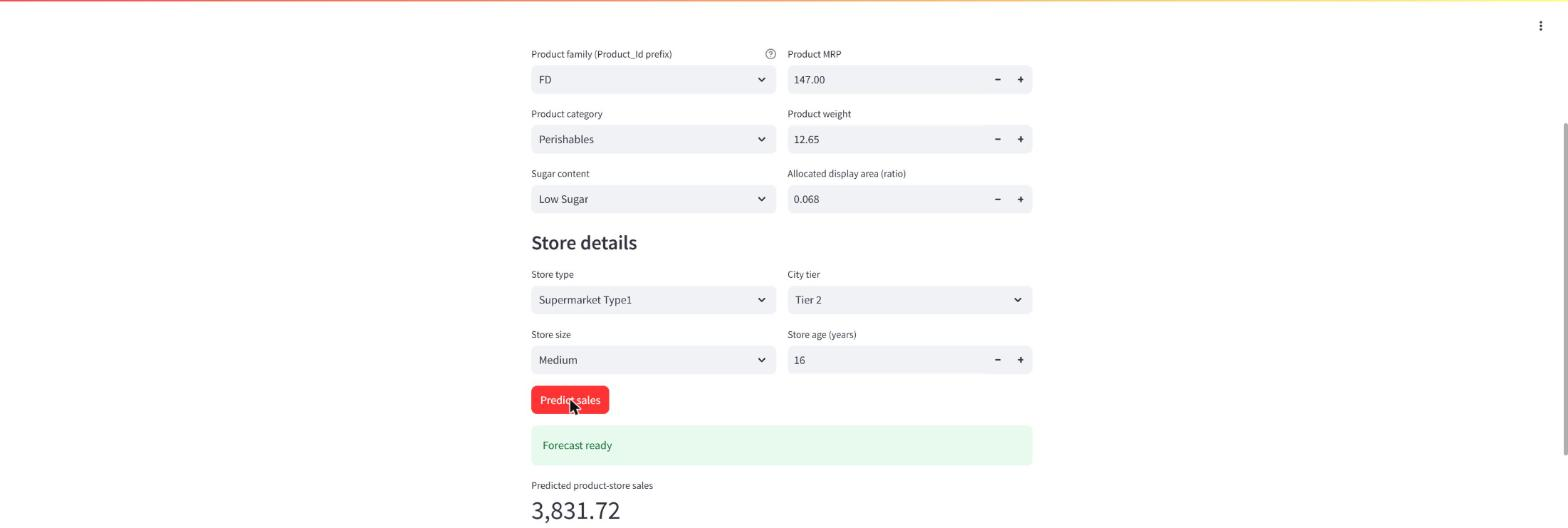

# **Actionable Insights and Business Recommendations**

### Model summary
- The final **Random Forest Tuned** model forecasts product–store sales with **R² ≈ 0.93** and **MAPE ≈ 3.7%** on unseen data (RMSE ≈ 283 against average sales of about 3,464). The forecasts are accurate enough to drive quarterly inventory and revenue planning.
- The model is deployed as two decoupled Docker containers, a Flask REST API and a Streamlit UI, connected over a Docker network. SuperKart's planning systems can call the API directly (single or batch), and business users can use the web interface without writing code.

### Key insights
1. **Price point is the main revenue lever.** MRP (r = 0.79) and product weight (r = 0.74) dominate the model. Revenue concentrates in higher-priced, larger-pack products.
2. **The store matters more than the product.** The same product type sells about 4,950 per item in the Tier 1 Departmental Store (OUT003) and about 1,760 in the Tier 3 Food Mart (OUT002), a gap of nearly 3× that holds for all 16 categories.
3. **OUT004 generates 50.8% of revenue on volume, not productivity.** It stocks 53% of the products but averages about 3,300 per product, about 33% below OUT003.
4. **Shelf space is not linked to sales.** Product_Allocated_Area has no relationship with revenue (r ≈ 0.00), so display space is currently allocated independently of what sells.
5. **Category mix is consistent across stores.** Fruits and Vegetables, Snack Foods, Dairy and Frozen Foods are the top revenue categories in every outlet.

### Business recommendations
1. **Plan inventory from the forecast, store by store.** Feed next quarter's planned assortment through the batch endpoint to get product–store revenue forecasts. Use them to set procurement quantities so that high-forecast items do not stock out and low-forecast items do not tie up working capital.
2. **Replicate the Departmental Store model in Tier 1 and Tier 2 cities.** OUT003's per-product productivity is the best in the chain. New store formats or refits of existing stores should start from its premium, higher-MRP assortment.
3. **Lift productivity at OUT004 rather than adding range.** Its revenue comes from breadth. Shifting part of its assortment towards higher-MRP and larger-pack lines, which the model links to higher sales, can raise revenue per product.
4. **Reposition the Tier 3 Food Mart (OUT002).** Its low sales come from a low-price assortment in a lower-income market. Value packs, bundles and larger pack sizes of everyday staples can raise basket value without moving out of its price segment.
5. **Re-allocate display space based on data.** Since shelf share does not currently relate to sales, run controlled tests that give more space to the top forecast items and top categories (Fruits and Vegetables, Snack Foods, Dairy), and measure the uplift.
6. **Prioritise supply-chain reliability for the top categories.** Perishable high-volume lines (Fruits and Vegetables, Dairy) need tighter replenishment cycles to avoid spoilage while protecting the largest revenue streams.

### Next steps for the forecasting solution
- **Retrain each quarter** on new sales data, and monitor the live API's error (MAPE) for drift.
- **Add time and promotion features** (season, holidays, discounts) once dated transactions are available. The current data is a cross-sectional snapshot, so seasonality cannot yet be modelled.
- **Expand store coverage.** With only four stores, store-level effects rest on a small sample. Adding outlets will make forecasts for new store profiles more reliable.